# EDA de la estación meteorológica 367

Estación Joaquín Vallejo (La Ladera, Medellín), en el mismo punto que la pluviométrica 35. Variables: humedad relativa `h`, temperatura `t`, presión `pr`, velocidad media `vv` y de ráfaga `vv_max`, dirección media `dv` y de ráfaga `dv_max`, precipitación `p` y la columna `calidad`. Periodo: 1 dic 2025 a 30 abr 2026, un registro por minuto, hora local (UTC-5).

Se usan las funciones del paquete `siata` (`datos.cargar`, `datos.regularizar`, `datos.agregar`, `datos.media_circular`) y las salidas de `python -m siata.pipeline` en `parte2/salidas/`: las banderas `b_<var>` y la traza `fallas.parquet` son el resultado de `calidad.evaluar` (el control propio). No se modifica el CSV crudo y no se interpola ningún hueco. La comparación de la lluvia con la 35 va en el notebook comparativo; aquí `p` solo se perfila.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import signal, stats

from siata import datos
from siata.datos import DIR_SALIDAS, ESTACIONES, VARIABLES

sns.set_theme(style="whitegrid", palette="colorblind")
COL = sns.color_palette("colorblind")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 11, "axes.labelsize": 10})
pd.set_option("display.width", 160)
FIGURAS = Path.cwd().parent / "figuras"
FIGURAS.mkdir(exist_ok=True)
PERIODO = "1 dic 2025 a 30 abr 2026, hora local"
MESES = {1: "ene", 2: "feb", 3: "mar", 4: "abr", 5: "may", 6: "jun", 7: "jul", 8: "ago", 9: "sep",
         10: "oct", 11: "nov", 12: "dic"}


def guardar(fig, nombre):
    """Figura para el informe: parte2/figuras/01_<nombre>.png."""
    fig.savefig(FIGURAS / f"01_{nombre}.png", dpi=110, bbox_inches="tight")


def etiqueta(v):
    return f"{VARIABLES[v]['nombre']} ({VARIABLES[v]['unidad']})"


def coma(x, f=".1f"):
    return format(x, f).replace(".", ",")


def eje_fechas(ax):
    ax.xaxis.set_major_locator(mdates.MonthLocator())
    ax.xaxis.set_major_formatter(plt.FuncFormatter(
        lambda x, _: f"{MESES[mdates.num2date(x).month]} {mdates.num2date(x).year}"))


def nombre_mes(periodos):
    return [f"{MESES[p.month]} {p.year}" for p in periodos]


def rachas(s):
    """Rachas de valores idénticos consecutivos (un NaN corta la racha)."""
    g = (s != s.shift()).cumsum()
    r = s.groupby(g).agg(valor="first", minutos="size")
    r["inicio"] = s.index.to_series().groupby(g).first().to_numpy()
    return r[r["valor"].notna()].reset_index(drop=True)


V = ESTACIONES["367"]["variables"]
crudo = datos.cargar("367")
d = datos.regularizar(crudo, "367")
m = pd.read_parquet(DIR_SALIDAS / "minutal_367.parquet")  # d + banderas del control propio (siata.calidad)
fallas = pd.read_parquet(DIR_SALIDAS / "fallas.parquet").query("codigo == '367'")
lluvia35 = pd.read_parquet(DIR_SALIDAS / "minutal_35.parquet")[["p1", "p2"]]
horario = pd.read_parquet(DIR_SALIDAS / "horario.parquet")
horario = horario[[c for c in horario if c.startswith("367_")]].rename(columns=lambda c: c[4:]).loc[d.index[0]:d.index[-1]]
# las salidas del pipeline corresponden al crudo regularizado
assert m.index.equals(d.index) and m[V].fillna(-1).eq(d[V].fillna(-1)).all().all()
cero = (m["vv"] == 0) & (m["vv_max"] == 0) & (m["dv"] == 0) & (m["dv_max"] == 0)  # las cuatro columnas de viento en 0
print("crudo:", crudo.shape, "| malla minutal:", d.shape, "| horario:", horario.shape)

crudo: (217397, 11) | malla minutal: (217440, 14) | horario: (3624, 8)


## A1. Perfilamiento

¿El índice temporal es regular, sin duplicados ni marcas fuera del minuto?

In [2]:
print("filas:", len(crudo), "| minutos esperados:", len(d), "| faltan:", len(d) - len(crudo))
print("primera y última marca:", crudo["fecha_hora"].min(), "|", crudo["fecha_hora"].max())
print("fechas no legibles:", crudo["fecha_hora"].isna().sum())
print("duplicados (codigo, fecha_hora):", crudo.duplicated(["codigo", "fecha_hora"]).sum(),
      "| filas idénticas:", crudo.duplicated().sum())
print("ordenado:", crudo["fecha_hora"].is_monotonic_increasing,
      "| marcas con segundos distintos de 0:", (crudo["fecha_hora"].dt.second != 0).sum())
paso = crudo["fecha_hora"].diff().dt.total_seconds().div(60)
print("paso entre registros consecutivos (min) -> veces:", paso.value_counts().sort_index().to_dict())
print("códigos de estación:", crudo["codigo"].unique())

filas: 217397 | minutos esperados: 217440 | faltan: 43
primera y última marca: 2025-12-01 00:00:00 | 2026-04-30 23:59:00
fechas no legibles: 0
duplicados (codigo, fecha_hora): 0 | filas idénticas: 0
ordenado: True | marcas con segundos distintos de 0: 0
paso entre registros consecutivos (min) -> veces: {1.0: 217374, 2.0: 4, 3.0: 16, 4.0: 1, 5.0: 1}
códigos de estación: [367]


El archivo trae 217 397 filas de 217 440 minutos esperados: faltan 43. No hay fechas ilegibles, duplicados ni marcas con segundos, y está ordenado. El paso es de 1 minuto en 217 374 casos; los 22 pasos de 2 a 5 minutos son los huecos de A2.

¿Qué tipos, rangos, nulos y centinelas tiene cada columna?

In [3]:
cols = V + ["calidad"]
perfil = pd.DataFrame({"tipo": crudo[cols].dtypes.astype(str), "nulos": crudo[cols].isna().sum(),
                       "-999": (crudo[cols] == -999).sum()})
perfil = perfil.join(crudo[V].describe(percentiles=[0.001, 0.5, 0.999]).T[["min", "0.1%", "50%", "99.9%", "max"]])
perfil["unidad"] = [VARIABLES[v]["unidad"] if v in VARIABLES else "código" for v in perfil.index]
perfil

,tipo,nulos,-999,min,0.1%,50%,99.9%,max,unidad
h,float64,0,0,35.94,39.79396,86.0,100.00000,100.00,%
t,float64,0,0,13.45,13.90000,18.3,27.76604,28.60,°C
pr,float64,0,0,809.51,810.10000,816.2,821.10000,821.80,hPa
vv,float64,0,0,0.00,0.02000,0.6,4.17000,13.47,m/s
vv_max,float64,0,0,0.00,0.20000,1.0,7.50000,14.30,m/s
dv,float64,0,0,0.00,0.00000,189.0,359.00000,359.00,grados
dv_max,float64,0,0,0.00,0.00000,216.0,360.00000,360.00,grados
p,float64,0,0,0.00,0.00000,0.0,0.18000,0.52,mm
calidad,int64,0,0,NaN,NaN,NaN,NaN,NaN,código


Ninguna columna tiene nulos ni el centinela -999, y todos los rangos son físicamente posibles: h de 35,94 a 100 %, t de 13,45 a 28,6 °C, pr de 809,51 a 821,8 hPa, `vv` hasta 13,47 m/s y `p` hasta 0,52 mm en un minuto. Que no haya -999 no quiere decir que no haya valores de relleno: los minutos con las cuatro columnas de viento en 0 se comportan como un centinela disfrazado (A3 y A5). Dos detalles para A5: el máximo de `vv` queda muy lejos de su percentil 99,9 (4,17 m/s), y `dv` llega a 359 mientras `dv_max` llega a 360.

¿Cuál es la resolución real de cada variable? El CSV trae dos decimales, pero eso no dice con qué paso mide el sensor.

In [4]:
def resolucion(x):
    x = x.dropna()
    c = (x * 100).round().astype("int64")  # el CSV trae a lo sumo 2 decimales
    return pd.Series({"valores distintos": x.nunique(),
                      "paso mínimo": np.diff(np.unique(c)).min() / 100,
                      "% enteros": 100 * (c % 100 == 0).mean(),
                      "% múltiplos de 0.1": 100 * (c % 10 == 0).mean()})

res = crudo[V].apply(resolucion).T
res["% enteros"] = res["% enteros"].round(1)
res["% múltiplos de 0.1"] = res["% múltiplos de 0.1"].round(1)
print("Si los valores estuvieran repartidos al azar en pasos de 0.01: 1 % enteros y 10 % múltiplos de 0.1")
res

Si los valores estuvieran repartidos al azar en pasos de 0.01: 1 % enteros y 10 % múltiplos de 0.1


,valores distintos,paso mínimo,% enteros,% múltiplos de 0.1
h,5707.0,0.01,55.1,59.3
t,1472.0,0.01,6.1,61.0
pr,1195.0,0.01,6.1,60.3
vv,547.0,0.01,0.6,10.1
vv_max,118.0,0.10,8.9,100.0
dv,360.0,1.00,100.0,100.0
dv_max,287.0,1.00,100.0,100.0
p,49.0,0.01,95.6,95.6


In [5]:
# ¿La mezcla de resoluciones cambia en el tiempo (por ejemplo, un cambio de datalogger)?
c = (crudo.set_index("fecha_hora")[["h", "t", "pr", "vv"]] * 100).round().astype("int64")
por_mes = pd.DataFrame({"h entero %": (c["h"] % 100 == 0), "t múltiplo 0.1 %": (c["t"] % 10 == 0),
                        "pr múltiplo 0.1 %": (c["pr"] % 10 == 0), "vv múltiplo 0.1 %": (c["vv"] % 10 == 0)})
por_mes = (100 * por_mes.groupby(por_mes.index.to_period("M")).mean()).round(1)
por_mes.index = nombre_mes(por_mes.index)
por_mes

,h entero %,t múltiplo 0.1 %,pr múltiplo 0.1 %,vv múltiplo 0.1 %
dic 2025,53.6,60.5,60.6,10.0
ene 2026,57.5,62.3,60.2,10.0
feb 2026,55.5,61.4,61.2,10.1
mar 2026,54.1,60.4,59.6,10.2
abr 2026,54.7,60.2,60.0,10.1


Si la resolución fuera 0,01, un 1 % de los valores serían enteros y un 10 % múltiplos de 0,1. En h el 55,1 % son enteros; en t y pr el 61,0 % y el 60,3 % son múltiplos de 0,1, y la proporción casi no cambia de un mes a otro (no hay señal de un cambio de equipo en el periodo). `vv` sí se comporta como 0,01 (10,1 %), `vv_max` va en pasos de 0,1 m/s y las direcciones en grados enteros.

Interpretación (inferida): el sensor entrega h en pasos de 1 %, t en 0,1 °C y pr en 0,1 hPa, que son las resoluciones de reporte de la OMM (OMM-8 Vol. I, 2023, Anexo 1.A, pp. 25 a 29), y el valor del minuto es el promedio de varias lecturas. Si todas las lecturas del minuto son iguales, el promedio queda en el entero o en el décimo; si cambian, aparecen los centésimos. Esto pesa en dos cosas: los valores repetidos son más probables de lo que parece con dos decimales, y un umbral de persistencia de 0,1 °C es igual al paso del sensor (A5).

## A2. Completitud temporal

¿Cuántos huecos hay, cuánto duran y cuándo ocurren?

In [6]:
falta = ~d["presente"]
bloque = (falta != falta.shift()).cumsum()
huecos = (d.index.to_series()[falta].groupby(bloque[falta])
          .agg(inicio="first", fin="last", minutos="size").reset_index(drop=True))
huecos["minuto_de_inicio"] = huecos["inicio"].dt.minute
completitud = 1 - falta.mean()
print(f"minutos sin registro: {falta.sum()} de {len(d)} | completitud {completitud:.4%} | huecos: {len(huecos)}")
print("duración de los huecos (min) -> cantidad:", huecos["minutos"].value_counts().sort_index().to_dict())
print("huecos que empiezan en el minuto :01 de la hora:", (huecos["minuto_de_inicio"] == 1).sum(),
      "| minutos sin registro entre las 11 y las 16 h:", falta[(d.index.hour >= 11) & (d.index.hour <= 16)].sum())
print("minutos sin registro por mes:", {MESES[p.month]: int(x) for p, x in falta.groupby(d.index.to_period("M")).sum().items()})
print("completitud diaria mínima:", f"{1 - falta.resample('D').mean().max():.4f}",
      "| días con algún hueco:", (falta.resample("D").sum() > 0).sum())
huecos

minutos sin registro: 43 de 217440 | completitud 99.9802% | huecos: 22
duración de los huecos (min) -> cantidad: {1: 4, 2: 16, 3: 1, 4: 1}
huecos que empiezan en el minuto :01 de la hora: 11 | minutos sin registro entre las 11 y las 16 h: 36
minutos sin registro por mes: {'dic': 11, 'ene': 18, 'feb': 8, 'mar': 6, 'abr': 0}
completitud diaria mínima: 0.9875 | días con algún hueco: 9


,inicio,fin,minutos,minuto_de_inicio
0,2025-12-02 11:01:00,2025-12-02 11:02:00,2,1
1,2025-12-02 12:01:00,2025-12-02 12:02:00,2,1
2,2025-12-02 13:01:00,2025-12-02 13:02:00,2,1
3,2025-12-02 14:01:00,2025-12-02 14:02:00,2,1
4,2025-12-02 15:01:00,2025-12-02 15:01:00,1,1
5,2025-12-07 16:01:00,2025-12-07 16:02:00,2,1
6,2026-01-08 11:11:00,2026-01-08 11:12:00,2,11
7,2026-01-08 11:26:00,2026-01-08 11:27:00,2,26
8,2026-01-08 11:35:00,2026-01-08 11:36:00,2,35
9,2026-01-08 11:47:00,2026-01-08 11:47:00,1,47


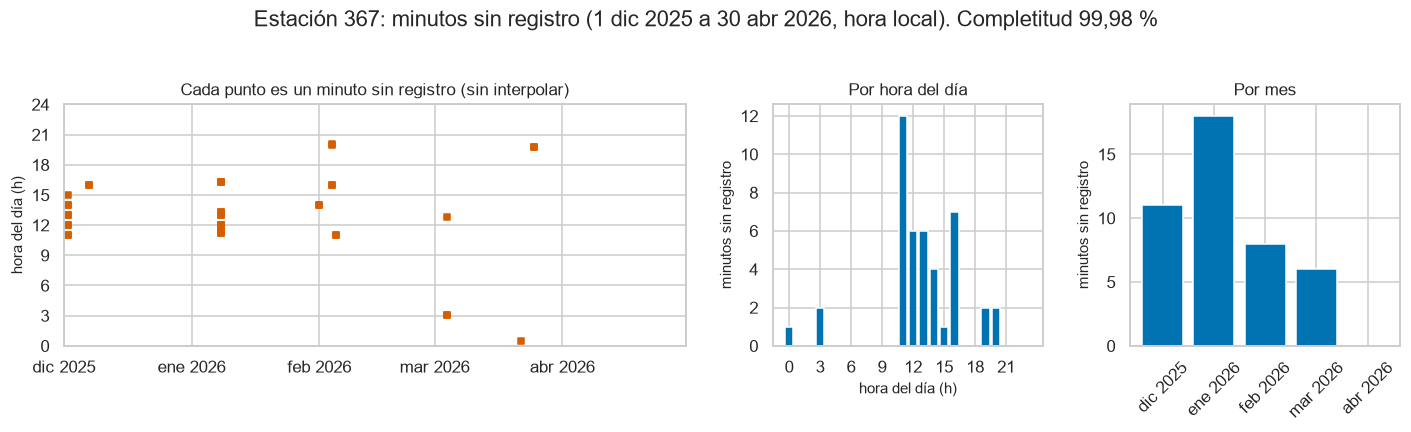

In [7]:
t_falta = d.index[falta]
fig, ax = plt.subplots(1, 3, figsize=(13, 3.8), gridspec_kw={"width_ratios": [2.3, 1, 1]})
ax[0].scatter(t_falta.normalize(), t_falta.hour + t_falta.minute / 60, s=16, marker="s", color=COL[3])
ax[0].set(ylim=(0, 24), yticks=range(0, 25, 3), xlim=(d.index[0], d.index[-1]), ylabel="hora del día (h)",
          title="Cada punto es un minuto sin registro (sin interpolar)")
eje_fechas(ax[0])
por_hora = falta.groupby(d.index.hour).sum().reindex(range(24), fill_value=0)
ax[1].bar(por_hora.index, por_hora.to_numpy(), color=COL[0])
ax[1].set(xlabel="hora del día (h)", ylabel="minutos sin registro", title="Por hora del día", xticks=range(0, 24, 3))
por_mes_f = falta.groupby(d.index.to_period("M")).sum().reindex(pd.period_range("2025-12", "2026-04", freq="M"), fill_value=0)
ax[2].bar(nombre_mes(por_mes_f.index), por_mes_f.to_numpy(), color=COL[0])
ax[2].set(ylabel="minutos sin registro", title="Por mes")
ax[2].tick_params(axis="x", rotation=45)
fig.suptitle(f"Estación 367: minutos sin registro ({PERIODO}). Completitud {coma(100 * completitud, '.2f')} %", y=1.03)
fig.tight_layout()
plt.show()

Hay 43 minutos sin registro en 22 huecos: 4 de 1 minuto, 16 de 2, uno de 3 y uno de 4. La completitud es 99,98 % y el peor día tiene 98,75 %; solo 9 días tienen algún hueco y abril no tiene ninguno. El patrón no es al azar: 11 de los 22 huecos empiezan en el minuto :01 de una hora (el 2 dic 2025 pasa cinco horas seguidas, de 11:01 a 15:01) y 36 de los 43 minutos caen entre las 11 y las 16 h. El 8 ene 2026 concentra 8 huecos entre las 11:11 y las 16:18. Inferido: una tarea horaria del datalogger o de la transmisión que a veces pisa los minutos :01 y :02. No afecta los análisis, pero sirve para el monitoreo: si los huecos en :01 se vuelven frecuentes, el problema está en la adquisición y no en el sensor.

## A3. Distribución de cada variable y de la columna calidad

¿Qué forma tiene cada variable y dónde están sus extremos?

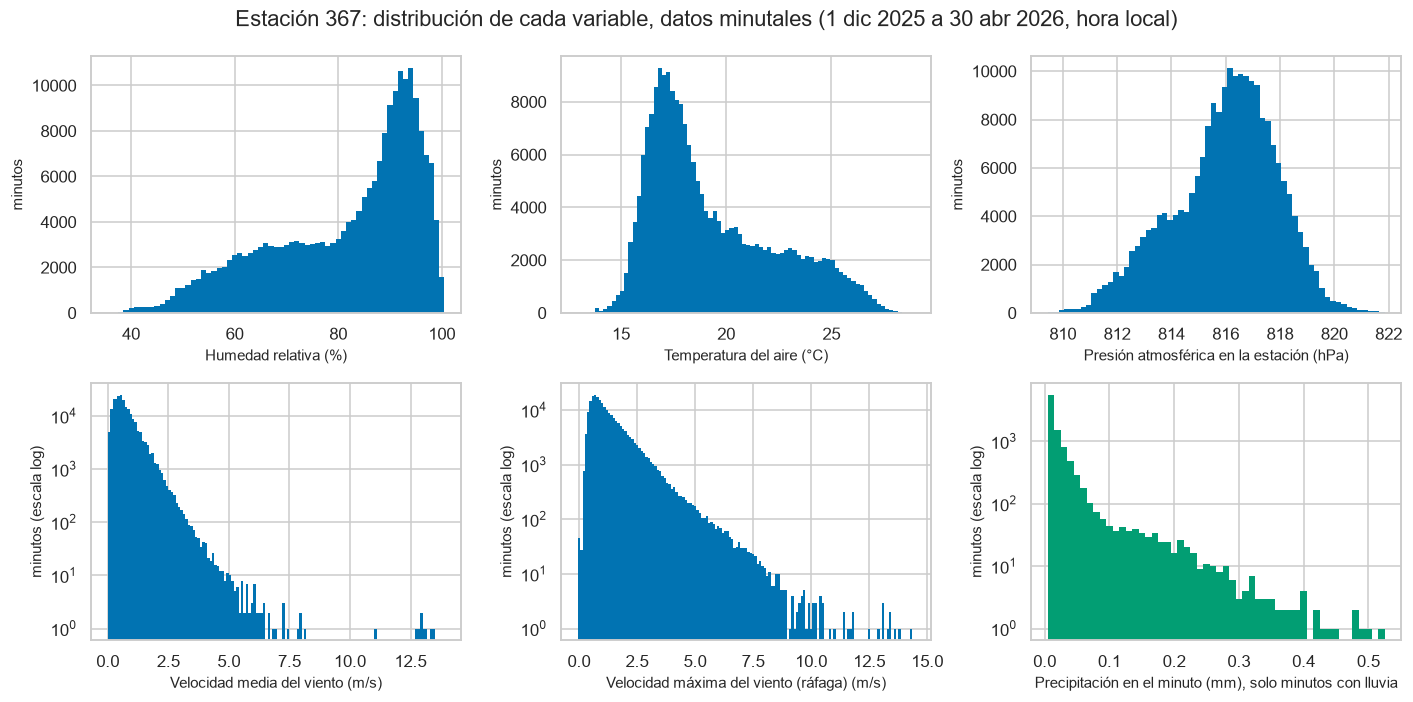

h = 100 exacto: 1363 | 99 < h < 100: 391 | 98 < h < 99: 922
vv > 8 m/s: 10 minutos | percentil 99.9 de vv: 4.17
minutos con lluvia: 9548 (4.39%) | de ellos con 0.01 mm: 5530 (57.9%) | máximo en un minuto: 0.52 mm | total: 268.6 mm
días con lluvia > 0: 132 | días con 1 mm o más: 68 | día más lluvioso: 2026-04-16 16.46 mm


In [8]:
fig, axs = plt.subplots(2, 3, figsize=(13, 6.5))
# bordes alineados con la resolución nativa (A1) para no fabricar dientes de sierra
config = {"h": np.arange(35.5, 101.5, 1), "t": np.arange(12.95, 29, 0.2), "pr": np.arange(809.45, 822, 0.2),
          "vv": np.arange(0, 14, 0.1), "vv_max": np.arange(-0.05, 14.5, 0.1)}
for ax, (v, bins) in zip(axs.flat, config.items()):
    ax.hist(d[v].dropna(), bins=bins, color=COL[0], linewidth=0)
    ax.set(xlabel=etiqueta(v), ylabel="minutos")
    if v.startswith("vv"):
        ax.set_yscale("log")
        ax.set_ylabel("minutos (escala log)")
lluvia = d["p"][d["p"] > 0]
axs[1, 2].hist(lluvia, bins=np.arange(0.005, 0.535, 0.01), color=COL[2], linewidth=0)
axs[1, 2].set(yscale="log", xlabel="Precipitación en el minuto (mm), solo minutos con lluvia",
              ylabel="minutos (escala log)")
fig.suptitle(f"Estación 367: distribución de cada variable, datos minutales ({PERIODO})")
fig.tight_layout()
plt.show()
print("h = 100 exacto:", (d["h"] == 100).sum(), "| 99 < h < 100:", ((d["h"] > 99) & (d["h"] < 100)).sum(),
      "| 98 < h < 99:", ((d["h"] > 98) & (d["h"] < 99)).sum())
print("vv > 8 m/s:", (d["vv"] > 8).sum(), "minutos | percentil 99.9 de vv:", d["vv"].quantile(0.999))
print("minutos con lluvia:", len(lluvia), f"({len(lluvia) / d['p'].notna().sum():.2%})",
      "| de ellos con 0.01 mm:", (lluvia.round(2) == 0.01).sum(), f"({(lluvia.round(2) == 0.01).mean():.1%})",
      "| máximo en un minuto:", lluvia.max(), "mm | total:", round(d["p"].sum(), 2), "mm")
diaria_p = d["p"].resample("D").sum()
print("días con lluvia > 0:", (diaria_p > 0).sum(), "| días con 1 mm o más:", (diaria_p >= 1).sum(),
      "| día más lluvioso:", diaria_p.idxmax().date(), diaria_p.max().round(2), "mm")

La humedad está cargada hacia valores altos, con 1363 minutos en 100 % exacto y ninguno por encima. La temperatura tiene una cola hacia arriba: las noches se concentran entre 16 y 18 °C y las tardes se reparten hasta 28,6 °C. La presión se mueve en una banda de 12 hPa. El viento es débil y en escala log muestra un grupo aislado cerca de 13 m/s: son los minutos del 5 mar 2026 (A5).

La lluvia es intermitente: 9548 minutos con lluvia (4,39 %), de los cuales 5530 (57,9 %) tienen 0,01 mm, el paso del sensor. El total es 268,6 mm en 132 días con lluvia, 68 de ellos con 1 mm o más; el día más lluvioso fue el 16 abr 2026 con 16,46 mm. Los bordes de los histogramas de t y pr van cada 0,2 para que la mezcla de resoluciones de A1 no fabrique dientes de sierra.

¿Cómo cambia la distribución a lo largo del día?

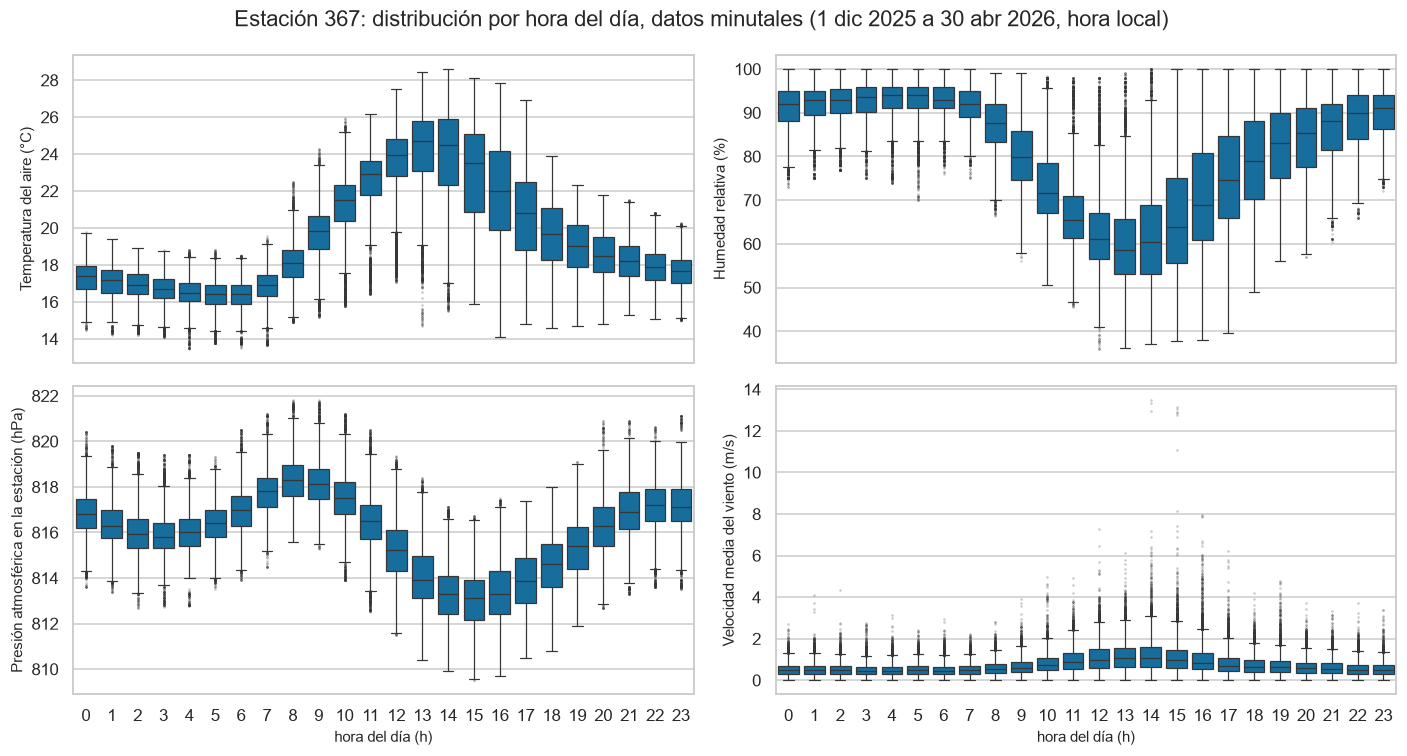

hora de la mediana máxima: {'t': 13, 'h': 4, 'pr': 8, 'vv': 13} | mínima: {'t': 6, 'h': 13, 'pr': 15, 'vv': 3}
rango de la mediana horaria: {'t': 8.31, 'h': 35.45, 'pr': 5.2, 'vv': 0.61}


In [9]:
fig, axs = plt.subplots(2, 2, figsize=(13, 7), sharex=True)
hora = d.index.hour
for ax, v in zip(axs.flat, ["t", "h", "pr", "vv"]):
    sns.boxplot(x=hora, y=d[v], ax=ax, color=COL[0], fliersize=0.6, linewidth=0.8,
                flierprops={"alpha": 0.3})
    ax.set(xlabel="hora del día (h)", ylabel=etiqueta(v))
fig.suptitle(f"Estación 367: distribución por hora del día, datos minutales ({PERIODO})")
fig.tight_layout()
plt.show()
mediana_hora = d[["t", "h", "pr", "vv"]].groupby(hora).median()
print("hora de la mediana máxima:", mediana_hora.idxmax().to_dict(), "| mínima:", mediana_hora.idxmin().to_dict())
print("rango de la mediana horaria:", (mediana_hora.max() - mediana_hora.min()).round(2).to_dict())

El ciclo diurno domina t, h y pr. La mediana de t va de su mínimo a las 6 h a su máximo a las 13 h (8,31 °C de diferencia) y la de h hace lo contrario (máximo a las 4 h, mínimo a las 13 h, 35,45 puntos). La presión tiene dos máximos y dos mínimos al día, con el máximo de la mediana a las 8 h y el mínimo a las 15 h (se analiza en A4). El viento es más fuerte cerca del mediodía y casi calmo de noche. La dispersión de t y h es mucho mayor de 12 a 17 h, la hora de la lluvia convectiva (A4).

¿Cómo cambia de un mes a otro?

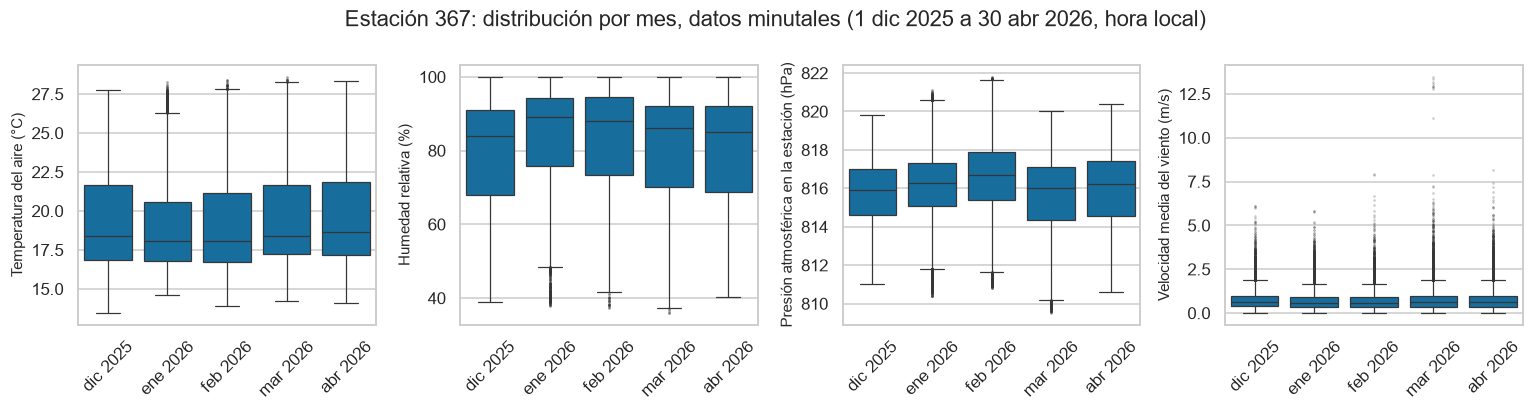

In [10]:
fig, axs = plt.subplots(1, 4, figsize=(14, 3.8))
mes = nombre_mes(d.index.to_period("M"))
orden = nombre_mes(pd.period_range("2025-12", "2026-04", freq="M"))
for ax, v in zip(axs, ["t", "h", "pr", "vv"]):
    sns.boxplot(x=mes, y=d[v], order=orden, ax=ax, color=COL[0], fliersize=0.6, linewidth=0.8,
                flierprops={"alpha": 0.3})
    ax.set(xlabel="", ylabel=etiqueta(v))
    ax.tick_params(axis="x", rotation=45)
fig.suptitle(f"Estación 367: distribución por mes, datos minutales ({PERIODO})")
fig.tight_layout()
plt.show()

Entre meses las distribuciones cambian poco, lo esperado en cinco meses de una zona tropical. Enero y febrero son los meses más húmedos (las cifras mensuales están en A4). Los atípicos más altos de `vv` en marzo (sobre 8 m/s) son el episodio del 5 mar.

¿De dónde sopla el viento y con qué fuerza, de día y de noche? La dirección es circular: se resume por sectores y con media vectorial ponderada por la velocidad, nunca con una media aritmética de 0 a 360.

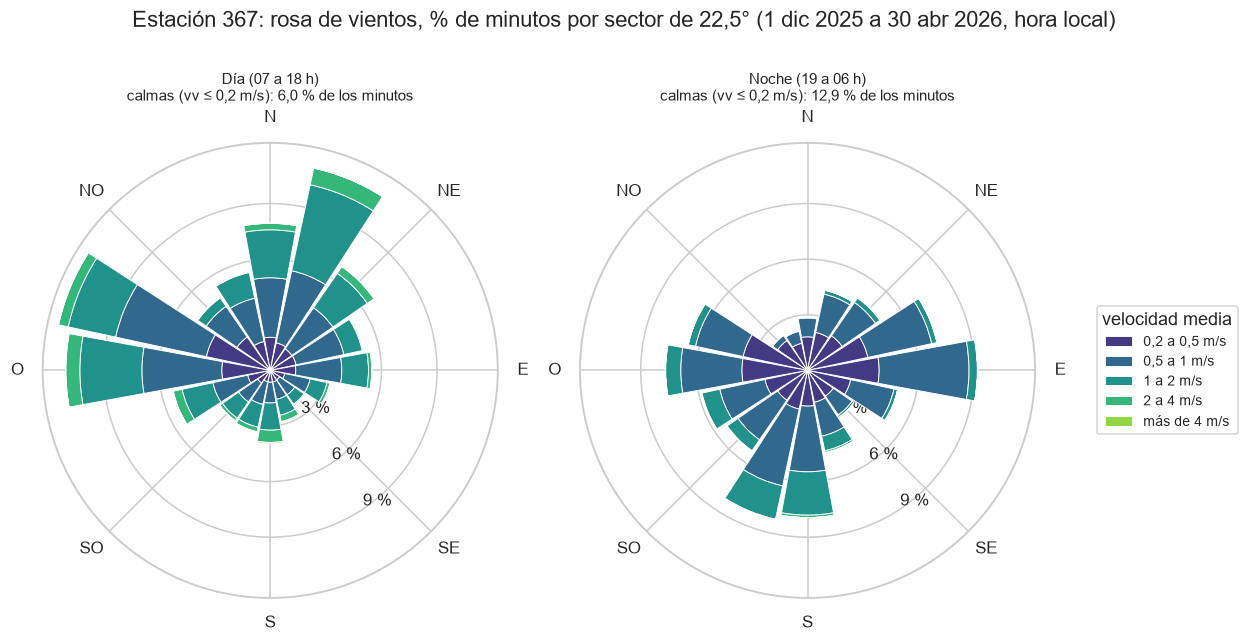

,minutos,calmas %,dirección media vectorial (°),constancia (0 a 1),sector más frecuente
Día (07 a 18 h),108638.0,6.0,331.2,0.21,292.5
Noche (19 a 06 h),108713.0,12.9,184.2,0.21,90.0


In [11]:
viento = m.loc[~cero, ["vv", "dv"]].dropna()  # los minutos con las cuatro columnas en 0 no son calma (ver A5)
calma = viento["vv"] <= 0.2  # OMM-8 Vol. I (2023), 5.1.2: calma si la velocidad media es <= 0,2 m/s
sector = (((viento["dv"] + 11.25) % 360) // 22.5).astype(int)  # 16 sectores, 0 = norte
cortes = [0.2, 0.5, 1, 2, 4, np.inf]
clases = ["0,2 a 0,5", "0,5 a 1", "1 a 2", "2 a 4", "más de 4"]
clase = pd.cut(viento["vv"], cortes, labels=clases)
de_dia = viento.index.hour.isin(range(7, 19))
colores = sns.color_palette("viridis", len(clases))
fig, axs = plt.subplots(1, 2, subplot_kw={"projection": "polar"}, figsize=(11.5, 5.6))
resumen_rosa = {}
grupos = [(axs[0], de_dia, "Día (07 a 18 h)"), (axs[1], ~de_dia, "Noche (19 a 06 h)")]
tablas = [pd.crosstab(sector[sel & ~calma], clase[sel & ~calma]).reindex(index=range(16), columns=clases, fill_value=0)
          / sel.sum() * 100 for _, sel, _ in grupos]
radio = max(t.sum(axis=1).max() for t in tablas) * 1.05  # misma escala en los dos paneles
for (ax, sel, nombre), tabla in zip(grupos, tablas):
    n = sel.sum()
    theta = np.deg2rad(np.arange(16) * 22.5)
    base = np.zeros(16)
    for color, c in zip(colores, clases):
        ax.bar(theta, tabla[c].to_numpy(), width=np.deg2rad(22.5) * 0.92, bottom=base, color=color,
               edgecolor="white", linewidth=0.6, label=f"{c} m/s")
        base += tabla[c].to_numpy()
    ax.set_theta_zero_location("N")
    ax.set_theta_direction(-1)
    ax.set_ylim(0, radio)
    ax.set_rlabel_position(146.25)
    ax.set_yticks([3, 6, 9])
    ax.set_xticks(np.deg2rad(np.arange(0, 360, 45)), ["N", "NE", "E", "SE", "S", "SO", "O", "NO"])
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0f} %"))
    media = datos.media_circular(viento.loc[sel, "dv"], pesos=viento.loc[sel, "vv"])
    u = (viento.loc[sel, "vv"] * np.sin(np.deg2rad(viento.loc[sel, "dv"]))).mean()
    w = (viento.loc[sel, "vv"] * np.cos(np.deg2rad(viento.loc[sel, "dv"]))).mean()
    constancia = np.hypot(u, w) / viento.loc[sel, "vv"].mean()
    resumen_rosa[nombre] = {"minutos": n, "calmas %": round(100 * calma[sel].mean(), 1),
                            "dirección media vectorial (°)": round(media, 1),
                            "constancia (0 a 1)": round(constancia, 2),
                            "sector más frecuente": tabla.sum(axis=1).idxmax() * 22.5}
    ax.set_title(f"{nombre}\ncalmas (vv ≤ 0,2 m/s): {coma(100 * calma[sel].mean())} % de los minutos", fontsize=10)
axs[1].legend(title="velocidad media", loc="center left", bbox_to_anchor=(1.12, 0.5), fontsize=9)
fig.suptitle(f"Estación 367: rosa de vientos, % de minutos por sector de 22,5° ({PERIODO})", y=1.02)
fig.tight_layout()
guardar(fig, "rosa_vientos")
plt.show()
pd.DataFrame(resumen_rosa).T

In [12]:
# Dirección media vectorial por hora del día (ponderada por la velocidad): ¿hay brisa de valle y montaña?
g = viento.groupby(viento.index.hour)
dir_hora = pd.DataFrame({
    "dirección media (°)": g.apply(lambda x: datos.media_circular(x["dv"], pesos=x["vv"])).round(0),
    "vv media (m/s)": g["vv"].mean().round(2),
    "calmas %": (100 * calma.groupby(viento.index.hour).mean()).round(1)})
dir_hora.index.name = "hora"
dir_hora

,dirección media (°),vv media (m/s),calmas %
hora,,,
0,206.0,0.54,13.1
1,199.0,0.54,13.0
2,189.0,0.53,13.7
3,180.0,0.50,14.3
4,166.0,0.49,15.7
5,159.0,0.52,14.3
6,183.0,0.50,14.9
7,282.0,0.53,11.6
8,286.0,0.60,9.9


El viento es flojo y su dirección depende de la hora. De día (07 a 18 h) el viento viene sobre todo del oeste-noroeste y del norte-noreste (sector más frecuente 292,5°, media vectorial 331°), con 6,0 % de calmas. De noche domina el oriente (sector más frecuente 90°) junto con el sur, con media vectorial de 184° y 12,9 % de calmas. La constancia es baja en los dos casos (0,21): el vector medio es apenas una quinta parte de la velocidad media. Por hora, la dirección media está entre 159° y 206° de 0 a 6 h, entre 282° y 345° de 7 a 14 h, y gira por el norte (21° a las 15 h) y el oriente (126° a las 16 h) hasta volver al sur en la noche.

Hipótesis, sin verificar con topografía: la estación está en la ladera oriental del valle, así que viento del occidente de día y del oriente de noche es lo que daría una brisa de ladera (sube de día, baja de noche); la componente sur nocturna sería el drenaje a lo largo del valle. Las calmas siguen el criterio de la OMM (velocidad media de 0,2 m/s o menos, OMM-8 Vol. I, 2023, 5.1.2, p. 207).

¿Con qué frecuencia aparece cada código de `calidad`, cuándo y con qué valores? El significado se infiere de los datos (después se contrastó con la guía oficial de la red meteorológica, P-GAA-SIATA-108, en el notebook 07).

In [13]:
frec = m["calidad"].value_counts().rename("minutos").to_frame()
frec["%"] = (100 * frec["minutos"] / frec["minutos"].sum()).round(3)
frec["días con el código"] = [m.index[m["calidad"] == c].normalize().nunique() for c in frec.index]
frec["primer día"] = [m.index[m["calidad"] == c].min().date() for c in frec.index]
frec["último día"] = [m.index[m["calidad"] == c].max().date() for c in frec.index]
frec

,minutos,%,días con el código,primer día,último día
calidad,,,,,
1.0,216712,99.685,151,2025-12-01,2026-04-30
1511.0,508,0.234,60,2026-01-01,2026-04-29
154.0,105,0.048,2,2026-01-31,2026-02-25
1567.0,72,0.033,4,2026-03-04,2026-04-27


In [14]:
# Mediana de cada variable según el código: ¿qué tiene de distinto cada código?
m.groupby("calidad")[V].median().round(2)

,h,t,pr,vv,vv_max,dv,dv_max,p
calidad,,,,,,,,
1.0,86.00,18.30,816.20,0.60,1.0,189.0,216.0,0.00
154.0,100.00,16.63,815.91,0.36,0.7,251.0,241.0,0.00
1511.0,86.00,18.60,817.00,0.62,1.2,227.0,232.0,0.01
1567.0,81.93,21.40,813.80,0.00,0.0,0.0,0.0,0.00


¿Qué regla parece estar detrás de cada código y se aplica igual en todo el periodo?

In [15]:
p01 = m["p"].round(2) == 0.01
seco35 = (lluvia35["p1"] == 0) & (lluvia35["p2"] == 0)
c1511 = m["calidad"] == 1511
print("1511: minutos", c1511.sum(), "| con p = 0.01 mm:", (p01 & c1511).sum(),
      f"| con la 35 en 0 en el mismo minuto: {seco35[c1511].mean():.1%}")
print("\nMinutos con p = 0.01 mm y la 35 en 0 en el mismo minuto, por mes y código de calidad:")
t1511 = pd.crosstab(m.index.to_period("M")[p01 & seco35], m.loc[p01 & seco35, "calidad"])
t1511.index = nombre_mes(t1511.index)
print(t1511)
c1567 = m["calidad"] == 1567
print("\n1567: minutos", c1567.sum(), "| con las cuatro columnas de viento en 0:", (c1567 & cero).sum(),
      "| minutos con las cuatro en 0 en todo el periodo:", cero.sum(),
      "| de ellos con otro código:", (cero & ~c1567).sum())
t_cero = m.index[cero]
dist = [np.abs((t - t_cero).total_seconds()).min() / 60 for t in m.index[c1567 & ~cero]]
print("1567 sin ceros: minutos", len(dist), "| distancia máxima al minuto en cero más cercano:", max(dist), "min")
print("días con 1567:", sorted({str(x.date()) for x in m.index[c1567]}))
lluvia_dia = {str(x.date()): round(m.loc[str(x.date()), "p"][c1567.loc[str(x.date())]].sum(), 2)
              for x in m.index[c1567].normalize().unique()}
print("lluvia de la 367 durante los minutos con 1567, por día (mm):", lluvia_dia)
sat = m["h"] == 100
c154 = m["calidad"] == 154
print("\n154: minutos", c154.sum(), "| con h = 100:", (c154 & sat).sum(), "| minutos con h = 100:", sat.sum(),
      f"| fracción de h = 100 con 154: {(c154 & sat).sum() / sat.sum():.1%}")
r100 = rachas(m["h"]).query("valor == 100")
r100["con_154"] = [int((m["calidad"].loc[i:i + pd.Timedelta(minutes=n - 1)] == 154).sum())
                   for i, n in zip(r100["inicio"], r100["minutos"])]
print("rachas de h = 100 de 30 min o más (y cuántos de sus minutos tienen 154):")
print(r100.query("minutos >= 30").sort_values("minutos", ascending=False).to_string(index=False))

1511: minutos 508 | con p = 0.01 mm: 508 | con la 35 en 0 en el mismo minuto: 98.8%

Minutos con p = 0.01 mm y la 35 en 0 en el mismo minuto, por mes y código de calidad:
calidad   1.0     1511.0  1567.0
dic 2025     653       0       0
ene 2026    1273      71       0
feb 2026     734     212       0
mar 2026    1062     120       1
abr 2026     843      99       0

1567: minutos 72 | con las cuatro columnas de viento en 0: 46 | minutos con las cuatro en 0 en todo el periodo: 46 | de ellos con otro código: 0
1567 sin ceros: minutos 26 | distancia máxima al minuto en cero más cercano: 9.0 min
días con 1567: ['2026-03-04', '2026-03-05', '2026-03-27', '2026-04-27']
lluvia de la 367 durante los minutos con 1567, por día (mm): {'2026-03-04': np.float64(0.03), '2026-03-05': np.float64(0.0), '2026-03-27': np.float64(0.1), '2026-04-27': np.float64(0.61)}

154: minutos 105 | con h = 100: 105 | minutos con h = 100: 1363 | fracción de h = 100 con 154: 7.7%
rachas de h = 100 de 30 min o más (y cu

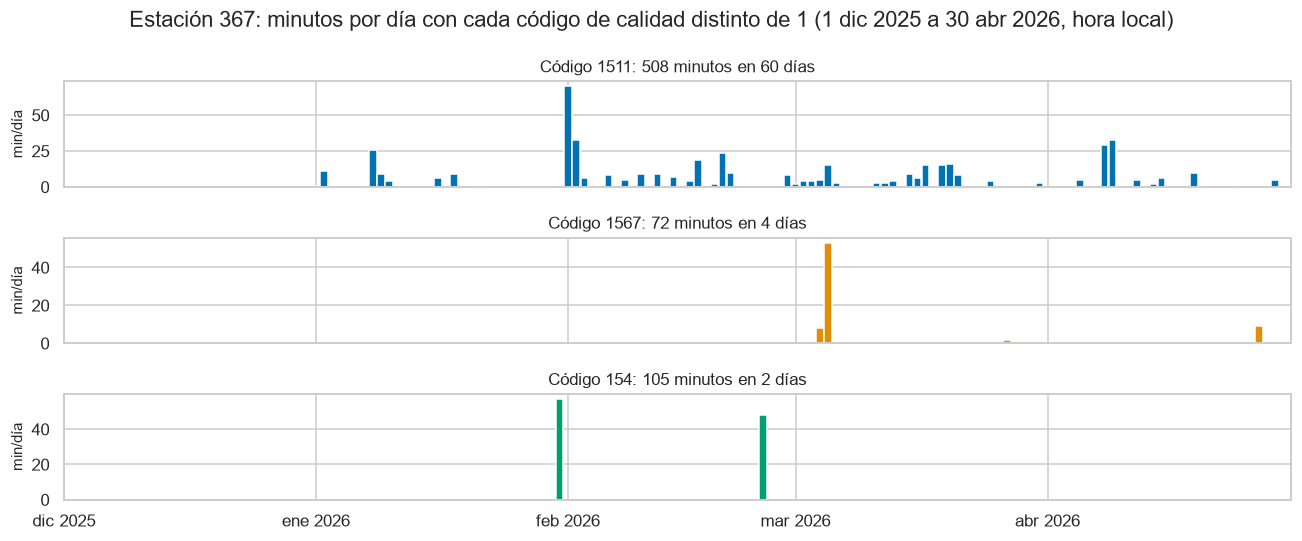

kappa SIATA vs control propio (periodo): 0.0529 | de lo que SIATA publica como confiable, fracción que el control propio no da por buena: 0.0248


In [16]:
codigos = [1511, 1567, 154]
fig, axs = plt.subplots(len(codigos), 1, figsize=(12, 5), sharex=True)
for ax, c, color in zip(axs, codigos, COL):
    por_dia = (m["calidad"] == c).resample("D").sum()
    ax.bar(por_dia.index, por_dia.to_numpy(), width=0.9, color=color)
    ax.set(ylabel="min/día", title=f"Código {c}: {int(por_dia.sum())} minutos en {int((por_dia > 0).sum())} días",
           xlim=(d.index[0], d.index[-1]))
eje_fechas(axs[-1])
fig.suptitle(f"Estación 367: minutos por día con cada código de calidad distinto de 1 ({PERIODO})")
fig.tight_layout()
plt.show()
ind = pd.read_csv(Path.cwd().parent / "resultados" / "indicadores_periodo.csv").query("codigo == 367")
print("kappa SIATA vs control propio (periodo):", ind["kappa"].iloc[0].round(4),
      "| de lo que SIATA publica como confiable, fracción que el control propio no da por buena:",
      ind["falsos_confiables"].iloc[0].round(4))

El 99,685 % de los minutos tiene calidad 1. Los otros tres códigos suman 685 minutos y cada uno responde a una regla distinta (inferido):

- 1511, lluvia mínima sin respaldo. Los 508 minutos tienen p = 0,01 mm y en el 98,8 % la 35, en el mismo sitio, marcó 0 en ese minuto. La regla no se aplicó en diciembre: ese mes hay 653 minutos con p = 0,01 mm y la 35 en 0, todos con calidad 1, y el primer 1511 es del 1 ene 2026. De enero a abril la mayoría de esos minutos también queda con 1 (por ejemplo, 1273 frente a 71 en enero), así que la regla tiene otra condición que no se puede reconstruir con estos datos.
- 1567, viento en cero. Los 46 minutos del periodo con `vv`, `vv_max`, `dv` y `dv_max` en 0 a la vez tienen 1567 y ninguno tiene otro código. Los otros 26 minutos con 1567 están a 9 minutos o menos de uno de esos ceros: el código marca el episodio completo. Solo hay 4 días: 4 y 5 mar, 27 mar y 27 abr 2026.
- 154, humedad saturada. Los 105 minutos tienen h = 100, pero son solo el 7,7 % de los 1363 minutos con h = 100. Marca dos rachas completas (31 ene y 25 feb 2026, de 57 y 48 minutos) y deja sin marcar rachas más largas, como la de 145 minutos del mismo 25 feb.

La columna marca casos puntuales, cambia de criterio en el tiempo y no cubre los problemas de A5 (la meseta de 13 m/s y la dirección de ráfaga salen con 1). El kappa entre `calidad` y el control propio es 0,053, y el 2,48 % de lo que SIATA publica como confiable no pasa el control propio. No sirve como etiqueta de verdad.

## A4. Ciclos diurnos y semanales, estacionalidad y tendencia

¿Cómo evolucionan los valores diarios en los cinco meses?

días sin valor diario (cobertura < 75 %): {'t': 0, 'h': 0, 'pr': 0, 'vv': 0, 'p': 0}


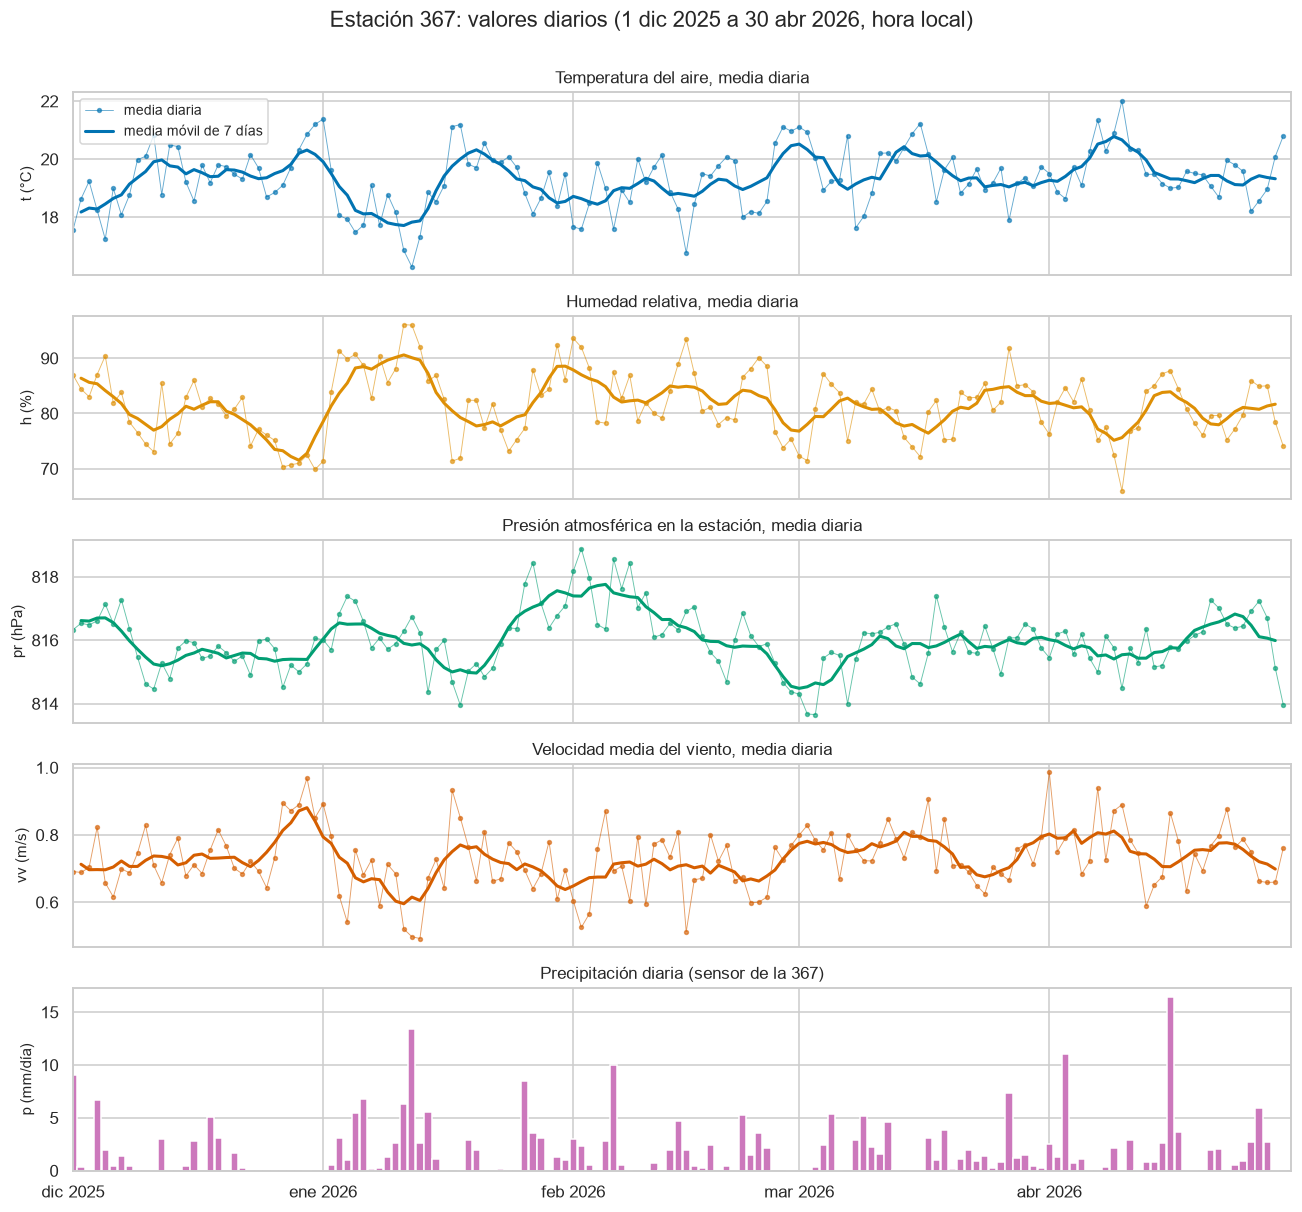

In [17]:
diario = pd.DataFrame({v: datos.agregar(d[v], v, "D", cobertura_min=0.75) for v in ["t", "h", "pr", "vv", "p"]})
print("días sin valor diario (cobertura < 75 %):", diario.isna().sum().to_dict())
fig, axs = plt.subplots(5, 1, figsize=(12, 11), sharex=True)
for ax, v, color in zip(axs, ["t", "h", "pr", "vv"], COL):
    ax.plot(diario.index, diario[v], marker="o", ms=2.5, lw=0.6, color=color, alpha=0.6, label="media diaria")
    ax.plot(diario.index, diario[v].rolling(7, center=True, min_periods=5).mean(), lw=2, color=color,
            label="media móvil de 7 días")
    ax.set(ylabel=f"{v} ({VARIABLES[v]['unidad']})", title=f"{VARIABLES[v]['nombre']}, media diaria")
axs[0].legend(loc="upper left", fontsize=9)
axs[4].bar(diario.index, diario["p"], width=0.9, color=COL[4])
axs[4].set(ylabel="p (mm/día)", title="Precipitación diaria (sensor de la 367)", xlim=(d.index[0], d.index[-1]))
eje_fechas(axs[4])
fig.suptitle(f"Estación 367: valores diarios ({PERIODO})", y=1.0)
fig.tight_layout()
plt.show()

In [18]:
mensual = diario.resample("MS").agg({"t": "mean", "h": "mean", "pr": "mean", "vv": "mean", "p": "sum"})
mensual["días con p >= 1 mm"] = (diario["p"] >= 1).resample("MS").sum()
mensual["amplitud diurna media de t (°C)"] = (d["t"].resample("D").max() - d["t"].resample("D").min()).resample("MS").mean()
mensual.index = nombre_mes(mensual.index)
print(mensual.round(2))
dias = (diario.index - diario.index[0]).days
for v in ["t", "h", "pr", "vv"]:
    ok = diario[v].notna()
    r = stats.linregress(dias[ok], diario[v][ok])
    print(f"{v}: pendiente lineal de la media diaria {30 * r.slope:+.3f} {VARIABLES[v]['unidad']} cada 30 días "
          f"(error estándar {30 * r.stderr:.3f}; sin corregir por autocorrelación)")

              t      h      pr    vv      p  días con p >= 1 mm  amplitud diurna media de t (°C)
dic 2025  19.39  79.07  815.72  0.75  36.92                   9                            10.35
ene 2026  18.97  84.07  816.12  0.69  72.98                  17                             8.83
feb 2026  19.05  83.50  816.53  0.69  45.10                  12                             9.13
mar 2026  19.57  80.74  815.64  0.75  50.35                  16                             9.88
abr 2026  19.66  80.02  815.92  0.76  63.25                  14                             9.99
t: pendiente lineal de la media diaria +0.131 °C cada 30 días (error estándar 0.058; sin corregir por autocorrelación)
h: pendiente lineal de la media diaria -0.275 % cada 30 días (error estándar 0.334; sin corregir por autocorrelación)
pr: pendiente lineal de la media diaria -0.017 hPa cada 30 días (error estándar 0.054; sin corregir por autocorrelación)
vv: pendiente lineal de la media diaria +0.008 m/s cada 30 d

Todos los días tienen cobertura suficiente (75 % o más). No hay una tendencia clara: la media mensual de t va de 18,97 °C (enero) a 19,66 °C (abril) y la pendiente lineal es +0,131 °C cada 30 días (error estándar 0,058, optimista porque los días están autocorrelacionados); en h, pr y vv la pendiente es menor que dos errores estándar. Lo que sí se ve son episodios de varios días, como la humedad alta de enero y la presión alta de comienzos de febrero. Enero fue el mes más húmedo y lluvioso en la 367 (84,07 % de humedad media, 72,98 mm y 17 días con 1 mm o más) y el de menor amplitud diurna de t (8,83 °C frente a 10,35 °C en diciembre). Con cinco meses y sin un año completo no se puede separar tendencia de estacionalidad: la pendiente de t describe solo este periodo.

¿Hay ciclo semanal? En variables naturales no debería haberlo; si apareciera, apuntaría a algo operativo.

In [19]:
dia_semana = diario.index.day_of_week
semana = diario.groupby(dia_semana).mean()
semana.index = ["lun", "mar", "mié", "jue", "vie", "sáb", "dom"]
semana["días"] = diario.groupby(dia_semana).size().to_numpy()
pruebas = pd.DataFrame({
    "p Kruskal-Wallis": [stats.kruskal(*[g.dropna() for _, g in diario[v].groupby(dia_semana)]).pvalue for v in diario],
    "rango entre días de la semana / desv. típica diaria": ((semana[diario.columns].max() - semana[diario.columns].min())
                                                            / diario.std()).to_numpy()}, index=diario.columns).T
print(semana.round(2))
pruebas.round(3)

         t      h      pr    vv     p  días
lun  19.02  82.39  816.22  0.70  2.64    22
mar  19.22  82.71  816.08  0.71  1.61    22
mié  19.52  80.58  815.84  0.74  1.23    22
jue  19.63  80.04  815.75  0.77  2.30    22
vie  19.27  82.02  815.96  0.73  2.22    21
sáb  19.61  80.06  815.84  0.75  0.93    21
dom  19.03  82.36  816.15  0.71  1.48    21


,t,h,pr,vv,p
p Kruskal-Wallis,0.310,0.509,0.726,0.063,0.704
rango entre días de la semana / desv. típica diaria,0.578,0.447,0.482,0.846,0.642


No hay ciclo semanal. Ninguna variable diaria cambia de forma significativa con el día de la semana (Kruskal-Wallis, p entre 0,063 y 0,726) y la diferencia entre el día más alto y el más bajo es menor que una desviación típica de la serie diaria (0,45 a 0,85 veces). Con 21 o 22 días por grupo, el viento (p = 0,063) queda cerca del límite y no se interpreta.

¿Cómo es el ciclo diurno medio y cambia entre meses?

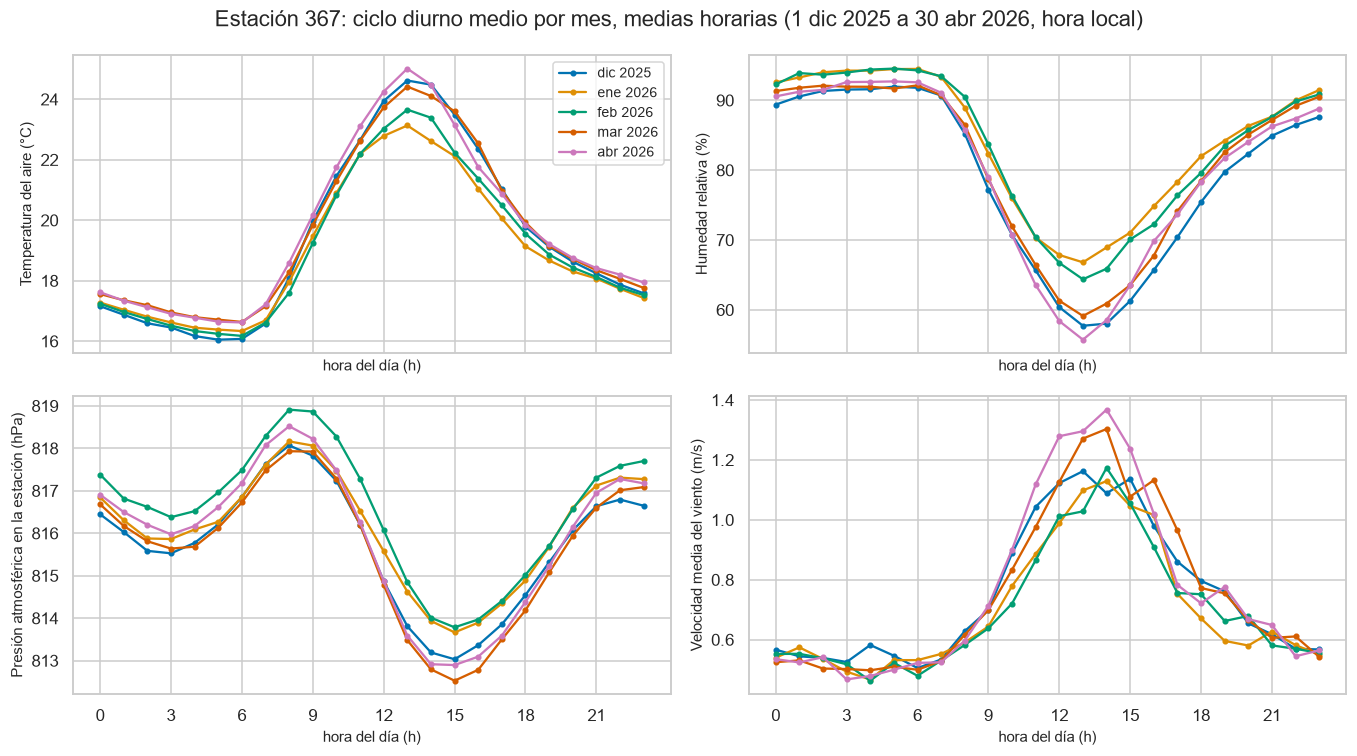

% de minutos con lluvia por hora del día: {0: 5.6, 1: 6.1, 2: 5.8, 3: 5.7, 4: 2.8, 5: 2.5, 6: 2.2, 7: 2.3, 8: 1.4, 9: 3.0, 10: 2.8, 11: 2.0, 12: 2.0, 13: 3.7, 14: 7.8, 15: 11.2, 16: 11.4, 17: 7.1, 18: 3.7, 19: 2.6, 20: 2.8, 21: 3.2, 22: 4.4, 23: 3.5}


In [20]:
# Ciclo diurno medio por mes con la serie horaria del pipeline (solo minutos con bandera buena)
fig, axs = plt.subplots(2, 2, figsize=(12.5, 7), sharex=True)
mes_h = horario.index.to_period("M")
for ax, v in zip(axs.flat, ["t", "h", "pr", "vv"]):
    ciclo = horario[v].groupby([mes_h, horario.index.hour]).mean().unstack(0)
    for color, periodo in zip(COL, ciclo.columns):
        ax.plot(ciclo.index, ciclo[periodo], marker="o", ms=3, lw=1.5, color=color,
                label=f"{MESES[periodo.month]} {periodo.year}")
    ax.set(xlabel="hora del día (h)", ylabel=etiqueta(v), xticks=range(0, 24, 3))
axs[0, 0].legend(fontsize=9)
fig.suptitle(f"Estación 367: ciclo diurno medio por mes, medias horarias ({PERIODO})")
fig.tight_layout()
plt.show()
lluvia_hora = (d["p"] > 0).groupby(d.index.hour).mean() * 100
print("% de minutos con lluvia por hora del día:", lluvia_hora.round(1).to_dict())

La forma del ciclo es la misma en los cinco meses y cambia la amplitud: enero tiene la tarde menos caliente y menos seca, en línea con su mayor lluvia. La lluvia es más frecuente de 14 a 17 h (entre 7,1 % y 11,4 % de los minutos con lluvia) que en la mañana (1,4 % a las 8 h), con un segundo máximo de 0 a 3 h (5,6 % a 6,1 %). El viento sube desde las 8 h, llega a su máximo a las 14 h (1,22 m/s de media, tabla horaria de A3) y baja de nuevo en la noche.

¿La presión tiene un ciclo de 12 h (marea atmosférica semidiurna) o solo el de 24 h? Se ajustan los armónicos de 24, 12 y 8 h a la anomalía horaria y se calcula un periodograma de Lomb-Scargle, que acepta los huecos sin interpolar. La temperatura sirve de contraste: su ciclo también tiene armónico de 12 h por su forma, pero no debería dominar.

In [21]:
def anomalia(s):
    """Quita la media móvil centrada de 24 h: deja intactos los armónicos de 24, 12 y 8 h."""
    return s - s.rolling(24, center=True, min_periods=18).mean()


def armonicos(s, k_max=3):
    """Ajuste por mínimos cuadrados de los armónicos diurnos (24/k h) a la anomalía horaria."""
    a = anomalia(s).dropna()
    x = a.index.hour.to_numpy() + 0.5  # la media horaria representa el centro de la hora
    X = [np.ones_like(x)]
    for k in range(1, k_max + 1):
        X += [np.cos(2 * np.pi * k * x / 24), np.sin(2 * np.pi * k * x / 24)]
    X = np.column_stack(X)
    coef, *_ = np.linalg.lstsq(X, a.to_numpy(), rcond=None)
    filas = {}
    for k in range(1, k_max + 1):
        ca, sb = coef[2 * k - 1], coef[2 * k]
        hora_max = (np.arctan2(sb, ca) * 24 / (2 * np.pi * k)) % (24 / k)
        pred_k = X[:, [2 * k - 1, 2 * k]] @ coef[[2 * k - 1, 2 * k]]
        filas[f"S{k} ({24 // k} h)"] = {"amplitud": np.hypot(ca, sb), "hora del máximo": hora_max,
                                        "% de la varianza de la anomalía": 100 * pred_k.var() / a.var()}
    return pd.DataFrame(filas).T, coef


tabla_arm = {}
for v in ["pr", "t"]:
    tab, coef = armonicos(horario[v])
    tabla_arm[v] = tab
    print(f"--- {etiqueta(v)} ---")
    print(tab.round(2))
    print("cociente de amplitudes S2/S1:", round(tab["amplitud"].iloc[1] / tab["amplitud"].iloc[0], 2), "\n")

# Periodograma de Lomb-Scargle: acepta series con huecos, no hace falta interpolar
periodos = np.geomspace(4, 48, 3000)
espectro = {}
for v in ["pr", "t"]:
    a = anomalia(horario[v]).dropna()
    horas = (a.index - a.index[0]).total_seconds().to_numpy() / 3600
    potencia = signal.lombscargle(horas, a.to_numpy() - a.mean(), 2 * np.pi / periodos)
    espectro[v] = potencia / potencia.max()
    picos, _ = signal.find_peaks(espectro[v], height=0.02)
    print(f"{v}: picos del periodograma (periodo en h: potencia relativa):",
          {round(periodos[i], 1): round(espectro[v][i], 3) for i in picos})

--- Presión atmosférica en la estación (hPa) ---
           amplitud  hora del máximo  % de la varianza de la anomalía
S1 (24 h)      1.47             4.76                            41.78
S2 (12 h)      1.52             9.59                            44.19
S3 (8 h)       0.19             1.10                             0.71
cociente de amplitudes S2/S1: 1.03 

--- Temperatura del aire (°C) ---
           amplitud  hora del máximo  % de la varianza de la anomalía
S1 (24 h)      3.36            14.49                            72.69
S2 (12 h)      1.32             1.20                            11.15
S3 (8 h)       0.24             4.77                             0.36
cociente de amplitudes S2/S1: 0.39 



pr: picos del periodograma (periodo en h: potencia relativa): {np.float64(11.9): np.float64(0.046), np.float64(12.0): np.float64(1.0), np.float64(12.1): np.float64(0.042), np.float64(23.6): np.float64(0.024), np.float64(23.8): np.float64(0.05), np.float64(24.0): np.float64(0.943), np.float64(24.2): np.float64(0.051), np.float64(24.4): np.float64(0.02)}


t: picos del periodograma (periodo en h: potencia relativa): {np.float64(12.0): np.float64(0.156), np.float64(23.8): np.float64(0.059), np.float64(24.0): np.float64(1.0), np.float64(24.2): np.float64(0.056), np.float64(24.4): np.float64(0.023)}


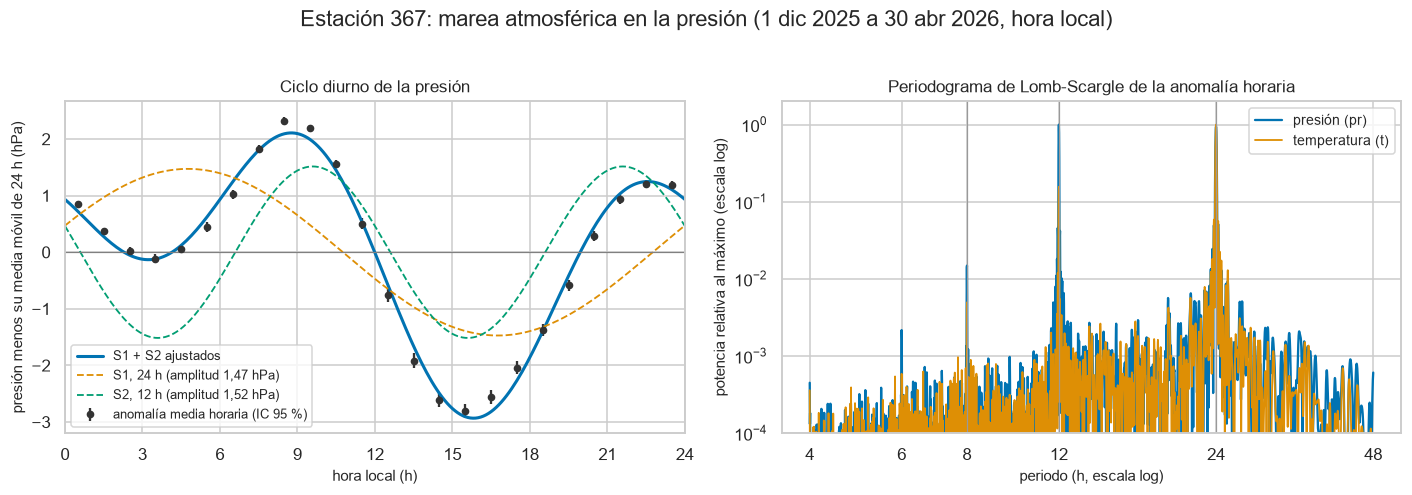

In [22]:
an_pr = anomalia(horario["pr"])
ciclo_pr = an_pr.groupby(an_pr.index.hour).agg(["mean", "sem"])
_, coef = armonicos(horario["pr"])
xx = np.linspace(0, 24, 241)
s1 = coef[1] * np.cos(2 * np.pi * xx / 24) + coef[2] * np.sin(2 * np.pi * xx / 24)
s2 = coef[3] * np.cos(4 * np.pi * xx / 24) + coef[4] * np.sin(4 * np.pi * xx / 24)
fig, axs = plt.subplots(1, 2, figsize=(13, 4.4))
axs[0].errorbar(ciclo_pr.index + 0.5, ciclo_pr["mean"], yerr=1.96 * ciclo_pr["sem"], fmt="o", ms=4,
                color="0.2", label="anomalía media horaria (IC 95 %)")
axs[0].plot(xx, s1 + s2 + coef[0], color=COL[0], lw=2, label="S1 + S2 ajustados")
axs[0].plot(xx, s1, color=COL[1], lw=1.2, ls="--", label=f"S1, 24 h (amplitud {coma(tabla_arm['pr']['amplitud'].iloc[0], '.2f')} hPa)")
axs[0].plot(xx, s2, color=COL[2], lw=1.2, ls="--", label=f"S2, 12 h (amplitud {coma(tabla_arm['pr']['amplitud'].iloc[1], '.2f')} hPa)")
axs[0].axhline(0, color="0.5", lw=0.8)
axs[0].set(xlabel="hora local (h)", ylabel="presión menos su media móvil de 24 h (hPa)", xticks=range(0, 25, 3),
           xlim=(0, 24), title="Ciclo diurno de la presión")
axs[0].legend(fontsize=8.5, loc="lower left")
axs[1].plot(periodos, espectro["pr"], color=COL[0], lw=1.5, label="presión (pr)")
axs[1].plot(periodos, espectro["t"], color=COL[1], lw=1.2, label="temperatura (t)")
for p in (24, 12, 8):
    axs[1].axvline(p, color="0.6", lw=0.8)
axs[1].set(xscale="log", yscale="log", xlabel="periodo (h, escala log)",
           ylabel="potencia relativa al máximo (escala log)", ylim=(1e-4, 2),
           title="Periodograma de Lomb-Scargle de la anomalía horaria")
axs[1].set_xticks([4, 6, 8, 12, 24, 48], ["4", "6", "8", "12", "24", "48"])
axs[1].xaxis.set_minor_formatter(plt.NullFormatter())
axs[1].legend(fontsize=9)
fig.suptitle(f"Estación 367: marea atmosférica en la presión ({PERIODO})", y=1.02)
fig.tight_layout()
guardar(fig, "presion_marea")
plt.show()

Sí hay marea semidiurna y es tan fuerte como el ciclo de 24 h. El armónico de 12 h (S2) tiene 1,52 hPa de amplitud y el de 24 h (S1) 1,47 hPa (cociente 1,03); juntos explican el 86 % de la varianza de la anomalía horaria (44,2 % y 41,8 %). S2 tiene sus máximos a las 9,6 h y a las 21,6 h. En el periodograma el pico más alto de la presión está en 12,0 h y el de 24 h es casi igual (0,943 del máximo). La temperatura es el control: su armónico de 12 h existe porque el ciclo no es una sinusoide, pero es mucho menor (cociente 0,39 y 0,156 de potencia relativa). La forma del calentamiento diurno no explica que en la presión el ciclo de 12 h iguale al de 24 h; eso lo hace la marea atmosférica semidiurna.

En la práctica, un control de salto o de tendencia de pr debe compararse con el ciclo esperado para la hora, y un modelo de pr necesita los dos armónicos.

¿Qué parte de la variación horaria es ciclo diurno y qué parte es variación de varios días? Esto orienta el modelado de la Tarea B.

In [23]:
# Descomposición aditiva sencilla de la serie horaria: media móvil de 24 h + ciclo diurno medio + residuo
filas = {}
for v in ["t", "h", "pr", "vv"]:
    s = horario[v]
    tendencia = s.rolling(24, center=True, min_periods=18).mean()
    an = s - tendencia
    diurno = an.groupby(an.index.hour).transform("mean")
    resto = an - diurno
    ok = s.notna() & tendencia.notna()
    var = s[ok].var()
    filas[v] = {"media móvil 24 h (sinóptico y estacional) %": 100 * tendencia[ok].var() / var,
                "ciclo diurno medio %": 100 * diurno[ok].var() / var, "residuo %": 100 * resto[ok].var() / var,
                "horas usadas": int(ok.sum())}
pd.DataFrame(filas).T.round(1)

,media móvil 24 h (sinóptico y estacional) %,ciclo diurno medio %,residuo %,horas usadas
t,12.7,72.6,13.4,3609.0
h,18.6,63.9,15.4,3558.0
pr,25.5,62.6,9.3,3610.0
vv,7.5,45.4,47.0,3561.0


El ciclo diurno medio explica la mayor parte de la varianza horaria de t (72,6 %), h (63,9 %) y pr (62,6 %). La variación de varios días (media móvil de 24 h) pesa más en la presión (25,5 %) que en t (12,7 %). En el viento el ciclo explica 45,4 % y el residuo 47,0 %: es la variable más ruidosa. Para la Tarea B, la referencia ingenua estacional de 24 h probablemente será difícil de superar en t, h y pr, y vv tendrá errores grandes con cualquier método. Los porcentajes no suman exactamente 100 porque las tres partes no son ortogonales.

## A5. Consistencia física e interna

¿La ráfaga es siempre mayor o igual que la media, y el factor de ráfaga es plausible?

In [24]:
print("vv_max < vv:", (m["vv_max"] < m["vv"]).sum(), "| vv_max == vv:", (m["vv_max"] == m["vv"]).sum())
factor = (m["vv_max"] / m["vv"]).where(m["vv"] >= 1)
print("factor de ráfaga vv_max / vv con vv >= 1 m/s:", factor.describe(percentiles=[0.01, 0.5, 0.99]).round(2).to_dict())
fuerte = m[(m["vv"] >= 5)]
bajo = fuerte.index[fuerte["vv_max"] / fuerte["vv"] < 1.1]
cerca = [np.abs((t - m.index[cero]).total_seconds()).min() / 60 <= 30 for t in bajo]
print(f"minutos con vv >= 5 m/s: {len(fuerte)} | con factor < 1.1: {len(bajo)} | de esos, a 30 min o menos de un minuto "
      f"con las cuatro columnas de viento en 0: {sum(cerca)} | días: {sorted({str(t.date()) for t in bajo})}")
salto_vv = m["vv"].diff()
print("mayores subidas de vv en un minuto (m/s):", salto_vv.nlargest(3).round(2).to_dict())
print("mayores bajadas de vv en un minuto (m/s):", salto_vv.nsmallest(3).round(2).to_dict())
print("\nLos 10 minutos con más viento medio:")
print(m.nlargest(10, "vv")[["vv", "vv_max", "dv", "dv_max", "t", "h", "pr", "p", "calidad", "b_vv"]].to_string())
print("calidad de SIATA en esos minutos con factor < 1.1:", m.loc[bajo, "calidad"].astype(int).value_counts().to_dict())

vv_max < vv: 0 | vv_max == vv: 70
factor de ráfaga vv_max / vv con vv >= 1 m/s: {'count': 48363.0, 'mean': 1.67, 'std': 0.44, 'min': 1.0, '1%': 1.14, '50%': 1.55, '99%': 3.24, 'max': 7.26}
minutos con vv >= 5 m/s: 90 | con factor < 1.1: 21 | de esos, a 30 min o menos de un minuto con las cuatro columnas de viento en 0: 20 | días: ['2026-03-04', '2026-03-05', '2026-03-17', '2026-04-27']
mayores subidas de vv en un minuto (m/s): {Timestamp('2026-03-05 14:57:00'): 11.14, Timestamp('2026-04-27 15:17:00'): 6.9, Timestamp('2026-03-05 16:32:00'): 6.43}
mayores bajadas de vv en un minuto (m/s): {Timestamp('2026-03-05 15:06:00'): -10.49, Timestamp('2026-03-05 16:33:00'): -7.9, Timestamp('2026-04-27 15:08:00'): -7.2}

Los 10 minutos con más viento medio:
                        vv  vv_max     dv  dv_max      t      h      pr     p  calidad  b_vv
fecha_hora                                                                                  
2026-03-05 14:59:00  13.47    13.6  267.0   267.0  19.01  8

La ráfaga nunca es menor que la media (0 casos) y es igual en 70 minutos. Con `vv` de 1 m/s o más, el factor de ráfaga `vv_max`/`vv` tiene mediana 1,55 y percentil 1 de 1,14. Con `vv` de 5 m/s o más, 21 de 90 minutos tienen factor menor que 1,1 y 20 de esos 21 están a 30 minutos o menos de un minuto con las cuatro columnas de viento en 0. El viento fuerte sin ráfaga aparece junto a la falla del anemómetro. El salto más grande de `vv` es +11,14 m/s (5 mar 2026, 14:57) y la bajada más grande es -10,49 m/s nueve minutos después.

¿Qué pasó el 5 mar 2026, el día con el viento medio más fuerte y con la mayoría de los minutos 1567?

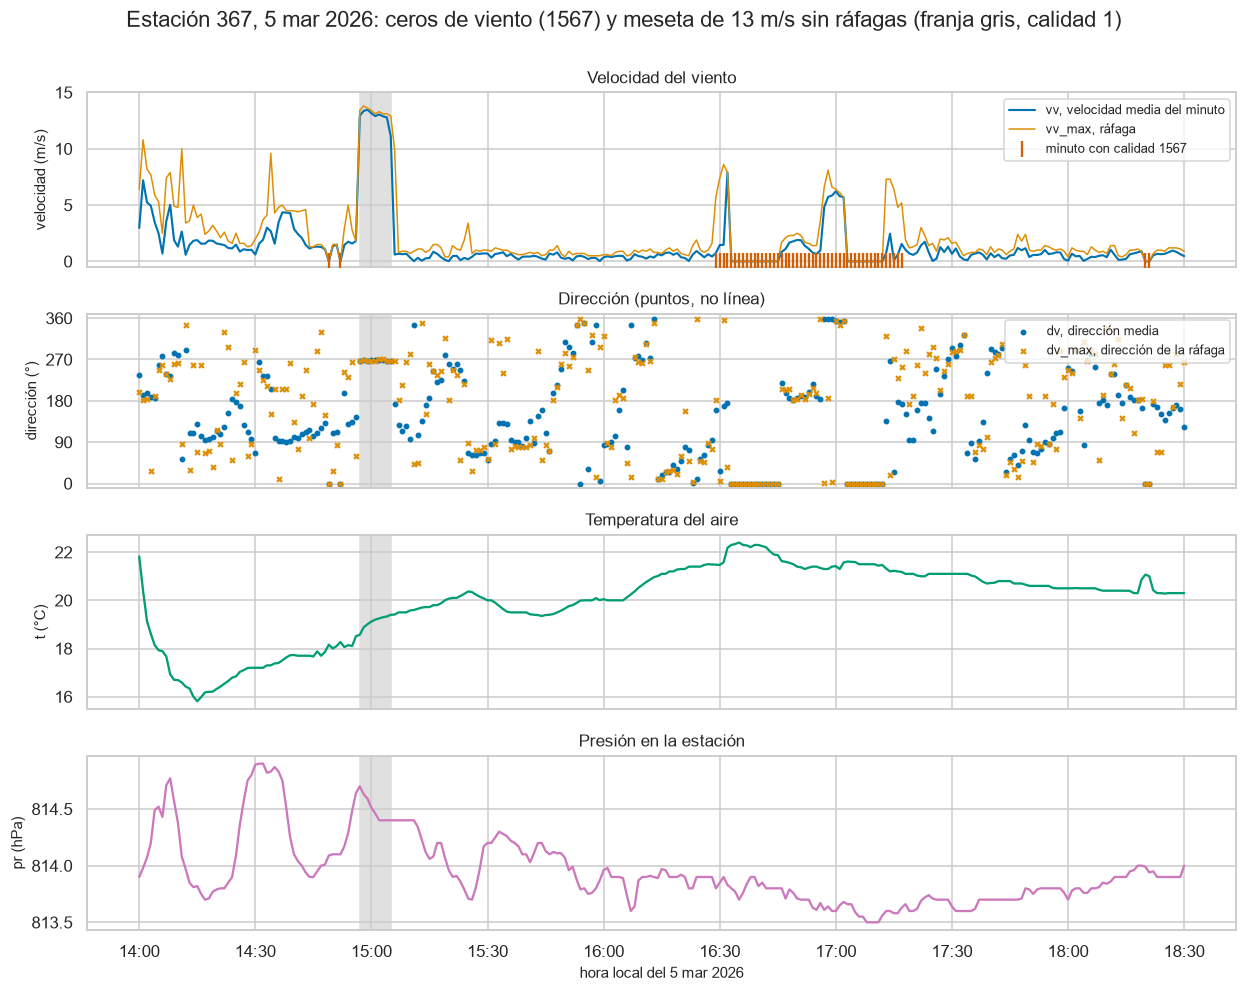

meseta 14:57 a 15:05 -> vv media 12.85 | desv. típica 0.69 | factor de ráfaga medio 1.037 | dv mín-máx 266.0 269.0 | calidad [1.] | bandera propia b_vv [3]
cambio de t en la meseta: 0.83 °C | cambio de pr: -0.3 hPa | lluvia 367: 0.02 mm | lluvia 35: 0.0 mm
ráfaga máxima del periodo: 14.3 m/s el 2026-02-05 16:21:00


In [25]:
w = m.loc["2026-03-05 14:00":"2026-03-05 18:30"]
meseta = slice(pd.Timestamp("2026-03-05 14:57"), pd.Timestamp("2026-03-05 15:05"))
fig, axs = plt.subplots(4, 1, figsize=(11.5, 9), sharex=True)
axs[0].plot(w.index, w["vv"], color=COL[0], lw=1.4, label="vv, velocidad media del minuto")
axs[0].plot(w.index, w["vv_max"], color=COL[1], lw=1, label="vv_max, ráfaga")
z = w.index[w["calidad"] == 1567]
axs[0].scatter(z, np.zeros(len(z)), marker="|", s=120, color=COL[3], label="minuto con calidad 1567", zorder=3)
axs[0].set(ylabel="velocidad (m/s)", ylim=(-0.5, 15), title="Velocidad del viento")
axs[0].legend(fontsize=8.5, loc="upper right")
axs[1].scatter(w.index, w["dv"], s=8, color=COL[0], label="dv, dirección media")
axs[1].scatter(w.index, w["dv_max"], s=10, marker="x", color=COL[1], label="dv_max, dirección de la ráfaga")
axs[1].set(ylabel="dirección (°)", ylim=(-10, 370), yticks=[0, 90, 180, 270, 360], title="Dirección (puntos, no línea)")
axs[1].legend(fontsize=8.5, loc="upper right")
axs[2].plot(w.index, w["t"], color=COL[2])
axs[2].set(ylabel="t (°C)", title="Temperatura del aire")
axs[3].plot(w.index, w["pr"], color=COL[4])
axs[3].set(ylabel="pr (hPa)", title="Presión en la estación", xlabel="hora local del 5 mar 2026")
for ax in axs:
    ax.axvspan(meseta.start, meseta.stop, color="0.88", zorder=0)
axs[3].xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
fig.suptitle("Estación 367, 5 mar 2026: ceros de viento (1567) y meseta de 13 m/s sin ráfagas (franja gris, calidad 1)",
             y=1.0)
fig.tight_layout()
plt.show()
e = m.loc[meseta]
print("meseta 14:57 a 15:05 -> vv media", e["vv"].mean().round(2), "| desv. típica", e["vv"].std().round(2),
      "| factor de ráfaga medio", (e["vv_max"] / e["vv"]).mean().round(3),
      "| dv mín-máx", e["dv"].min(), e["dv"].max(), "| calidad", e["calidad"].unique(), "| bandera propia b_vv", e["b_vv"].unique())
print("cambio de t en la meseta:", round(e["t"].iloc[-1] - e["t"].iloc[0], 2), "°C | cambio de pr:",
      round(e["pr"].iloc[-1] - e["pr"].iloc[0], 2), "hPa | lluvia 367:", e["p"].sum().round(2),
      "mm | lluvia 35:", lluvia35.loc[meseta].max(axis=1).sum().round(3), "mm")
print("ráfaga máxima del periodo:", m["vv_max"].max(), "m/s el", m["vv_max"].idxmax())

De 14:57 a 15:05 la velocidad salta a 12,94 m/s, se queda en 12,85 m/s de media (desviación típica 0,69) con dirección fija entre 266° y 269° y una ráfaga apenas 3,7 % mayor que la media, y cae a 0,61 m/s en un minuto. Antes y después hay minutos con las cuatro columnas en 0 (1567) y, entre ellos, picos cortos de viento con `vv` casi igual a `vv_max`. En la meseta la temperatura sube 0,83 °C, la presión baja 0,3 hPa y la 35 no registra lluvia, aunque sí llovió en la media hora alrededor (3,05 mm en la 35 de 14:35 a 15:25, ver la comparación de abajo). SIATA publica la meseta con calidad 1; el control propio marca sus nueve minutos como sospechosos (bandera 3), por la prueba de salto en los bordes y por la regla de factor de ráfaga en el resto. Lo clasifico como falla del sensor. La ráfaga máxima del periodo (14,3 m/s) es del 5 feb 2026 y se compara abajo.

¿Cómo se registran las calmas y qué convención usa la dirección para el norte (0 o 360)?

In [26]:
print("vv = 0:", (m["vv"] == 0).sum(), "| de ellos con las cuatro columnas en 0:", (cero & (m["vv"] == 0)).sum(),
      "| vv = 0 con vv_max > 0 y dv > 0:", ((m["vv"] == 0) & (m["vv_max"] > 0) & (m["dv"] > 0)).sum())
calmas = (m["vv"] <= 0.2) & ~cero
print(f"calmas (vv <= 0.2 m/s, sin los ceros de 1567): {calmas.sum()} ({calmas.mean():.2%})",
      "| con dirección distinta de 0:", (calmas & (m["dv"] > 0)).sum())
print("\nConvención 0/360 (minutos):")
print(pd.DataFrame({v: {"= 0": (m[v] == 0).sum(), "= 0 sin los ceros de 1567": ((m[v] == 0) & ~cero).sum(),
                        "= 360": (m[v] == 360).sum(), "máximo": m[v].max()} for v in ["dv", "dv_max"]}))

vv = 0: 67 | de ellos con las cuatro columnas en 0: 46 | vv = 0 con vv_max > 0 y dv > 0: 21
calmas (vv <= 0.2 m/s, sin los ceros de 1567): 20500 (9.43%) | con dirección distinta de 0: 20464

Convención 0/360 (minutos):
                              dv  dv_max
= 0                        592.0   306.0
= 0 sin los ceros de 1567  546.0   260.0
= 360                        0.0   608.0
máximo                     359.0   360.0


Hay dos tipos de velocidad cero. Los 21 minutos con `vv` = 0 tienen ráfaga y dirección: son calmas dentro del minuto. Los 46 con las cuatro columnas en 0 son la falla del anemómetro que SIATA marca con 1567 (A3) y no se cuentan como calma (se excluyeron de la rosa). Con el criterio de la OMM (0,2 m/s o menos) hay 20 500 minutos de calma (9,43 %) y en 20 464 la estación reporta una dirección distinta de 0. La OMM pide codificar la calma con dirección 00 (OMM-8 Vol. I, 2023, 5.1.2, p. 207); aquí la dirección en calma es ruido de la veleta, y por eso la dirección se resume con media vectorial ponderada por la velocidad.

Convención 0/360: `dv` va de 0 a 359 y nunca vale 360; `dv_max` usa las dos, con 260 minutos en 0 (sin los ceros de 1567) y 608 en 360. Es el mismo norte, pero una regla de rango o un conteo por grado sin normalizar los trata distinto. Recomendación: normalizar con `% 360` y reservar el 0 para la calma.

¿La dirección de la ráfaga es coherente con la dirección media?

In [27]:
con_viento = m["vv"] > 1.5
dif = ((m["dv_max"] - m["dv"] + 180) % 360 - 180).abs()  # diferencia angular en [0, 180]
acuerdo = (pd.DataFrame({"sector de dv": (m["dv"] // 45 * 45).astype("Int64"), "dif": dif})[con_viento]
           .groupby("sector de dv")["dif"]
           .agg(minutos="size", mediana_dif="median", pct_a_menos_de_22=lambda x: 100 * (x <= 22.5).mean()))
print("Coincidencia entre dirección media y de ráfaga, minutos con vv > 1.5 m/s, por sector de 45° de dv:")
print(acuerdo.round(1))
grados = lambda v, a, b: m.loc[~cero & (m[v] >= a) & (m[v] < b), v]
for a, b in [(0, 90), (90, 180), (180, 270), (270, 361)]:
    print(f"[{a}, {b}): dv toma {grados('dv', a, b).nunique()} valores ({len(grados('dv', a, b))} min); "
          f"dv_max toma {grados('dv_max', a, b).nunique()} valores ({len(grados('dv_max', a, b))} min)")
print("valores de dv_max en [90, 180):", sorted(grados("dv_max", 90, 180).astype(int).unique()))
mes_se = (m.loc[~cero, "dv_max"].between(90, 179.5)).groupby(m.index[~cero].to_period("M")).mean()
print("fracción de minutos con dv_max en [90, 180) por mes:", {MESES[p.month]: round(x, 3) for p, x in mes_se.items()})

Coincidencia entre dirección media y de ráfaga, minutos con vv > 1.5 m/s, por sector de 45° de dv:
              minutos  mediana_dif  pct_a_menos_de_22
sector de dv                                         
0                4973          5.0               96.9
45                836         10.0               74.8
90               1036         79.0               19.6
135              2474         65.0               26.8
180              2204         10.0               78.4
225              2576          8.0               91.1
270              2749          6.0               96.9
315               942          7.0               95.0
[0, 90): dv toma 90 valores (62452 min); dv_max toma 88 valores (70838 min)
[90, 180): dv toma 90 valores (40168 min); dv_max toma 22 valores (9687 min)
[180, 270): dv toma 90 valores (55028 min); dv_max toma 88 valores (68631 min)
[270, 361): dv toma 90 valores (59703 min); dv_max toma 89 valores (68195 min)
valores de dv_max en [90, 180): [np.int64(93), np.

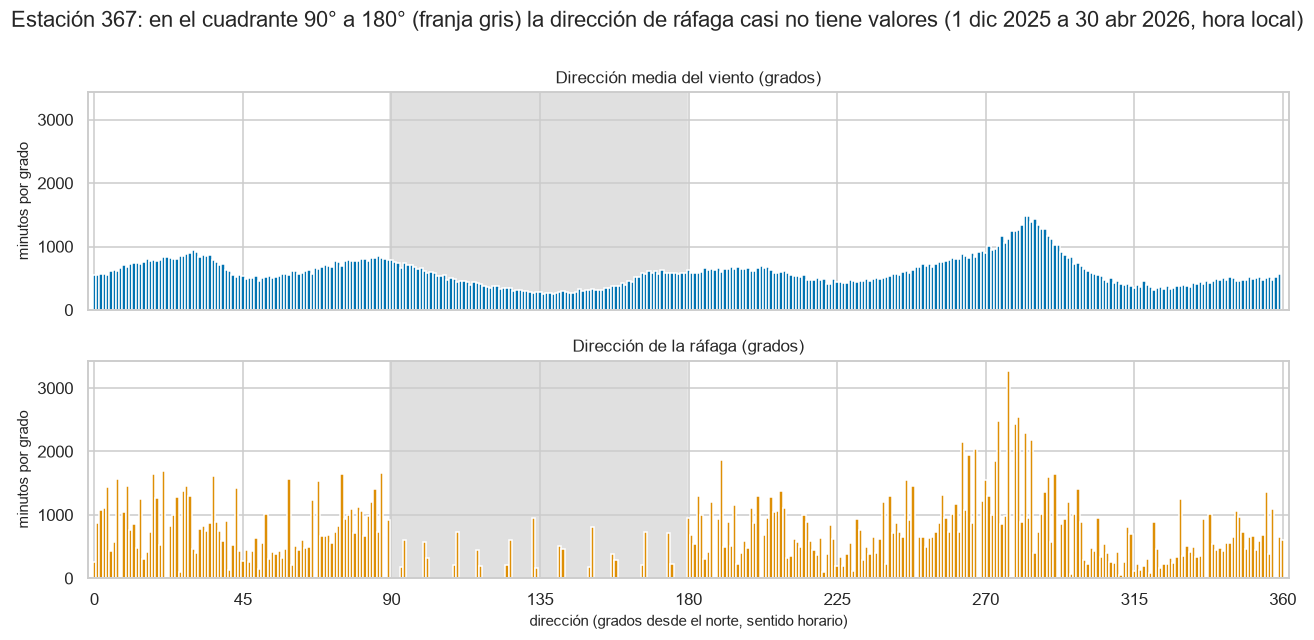

In [28]:
fig, axs = plt.subplots(2, 1, figsize=(12, 5.8), sharex=True, sharey=True)
for ax, v, color in [(axs[0], "dv", COL[0]), (axs[1], "dv_max", COL[1])]:
    cuenta = m.loc[~cero, v].dropna().astype(int).value_counts().reindex(range(361), fill_value=0)
    ax.bar(cuenta.index, cuenta.to_numpy(), width=1.0, color=color)
    ax.axvspan(89.5, 179.5, color="0.88", zorder=0)
    ax.set(ylabel="minutos por grado", title=f"{etiqueta(v)}")
axs[1].set(xlabel="dirección (grados desde el norte, sentido horario)", xlim=(-2, 362), xticks=range(0, 361, 45))
fig.suptitle(f"Estación 367: en el cuadrante 90° a 180° (franja gris) la dirección de ráfaga casi no tiene valores ({PERIODO})",
             y=1.0)
fig.tight_layout()
guardar(fig, "dv_max_cuadrante")
plt.show()

No en el cuadrante 90° a 180° (oriente a sur). Ahí `dv_max` solo toma 22 valores (93, 94, 100, 101, ..., 174, 175: dos de cada 7 a 9 grados) y tiene 9687 minutos, frente a 40 168 de `dv` en el mismo cuadrante; en los otros cuadrantes `dv_max` toma 88 o 89 valores. Con viento medio de ese cuadrante, la ráfaga queda a menos de 22,5° de la dirección media solo en el 19,6 % (90° a 135°) y el 26,8 % (135° a 180°) de los minutos, frente a 74,8 % a 96,9 % en los demás sectores. El patrón es el mismo los cinco meses (4,2 % a 4,8 % de los minutos con `dv_max` en ese cuadrante). Parece un error de codificación o de conversión de `dv_max` en el datalogger o en el procesamiento, más que un fenómeno físico (inferido). Sale con calidad 1 y el control propio no lo detecta. Mientras se corrige, `dv_max` no sirve para analizar direcciones.

¿Cómo se distingue un viento extremo real de una falla? Se comparan la ráfaga máxima del periodo (5 feb 2026) y la meseta del 5 mar, con la misma escala en cada fila.

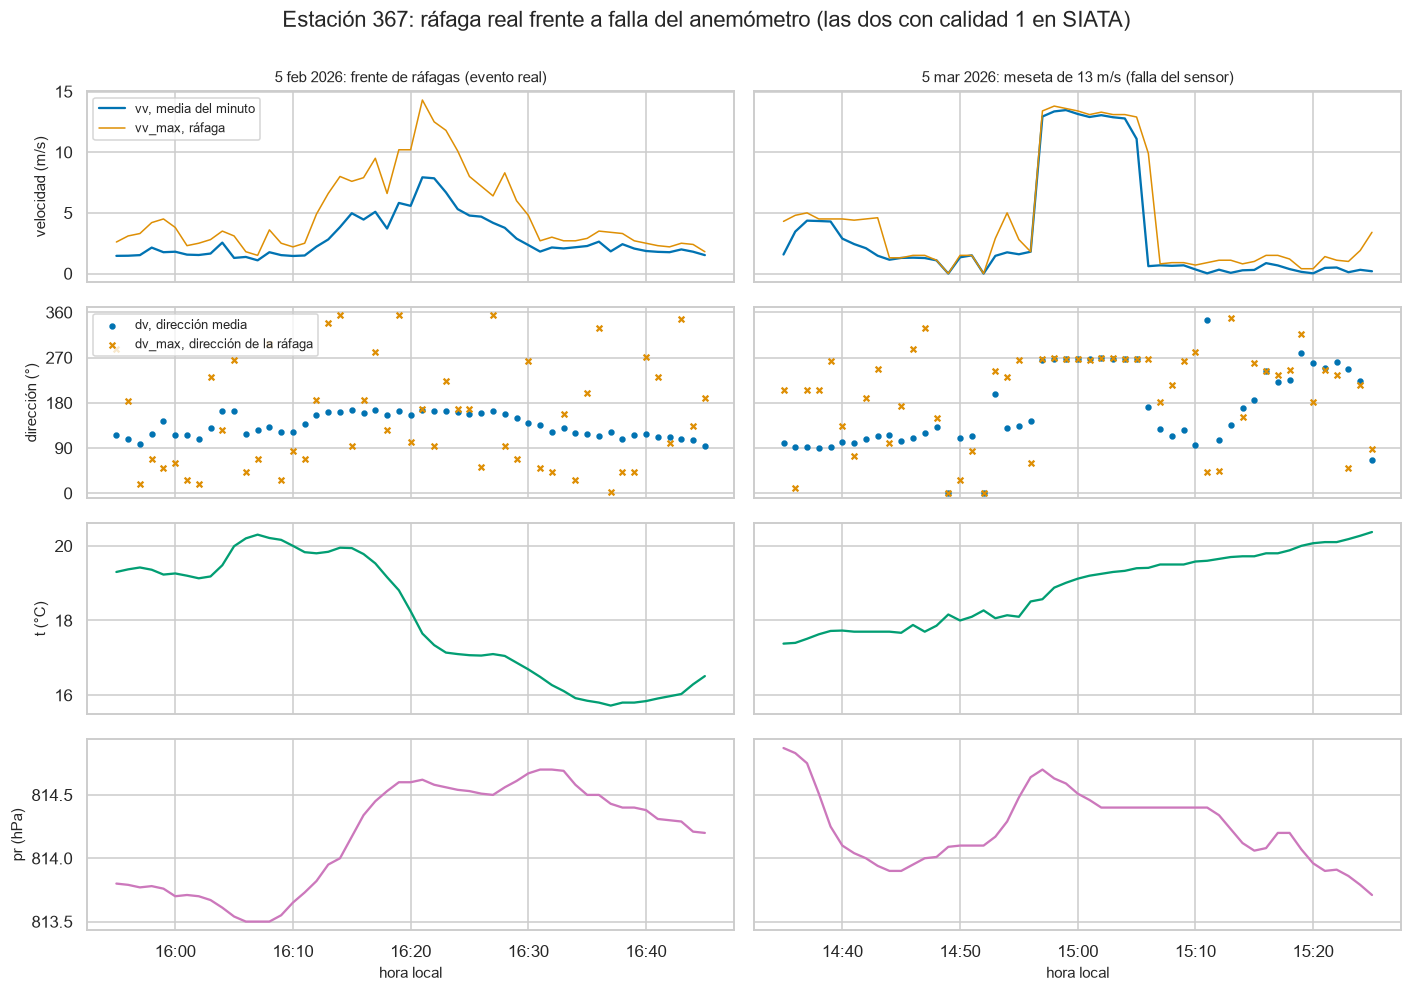

,5 feb 2026,5 mar 2026
vv máxima (m/s),7.93,13.47
vv_max máxima (m/s),14.3,13.8
factor de ráfaga medio con vv >= 5,1.786925,1.037343
mayor cambio de vv en un minuto (m/s),2.35,11.14
"cambio de t, 10 min después menos 10 min antes (°C)",-2.07,1.057
"cambio de pr, 10 min después menos 10 min antes (hPa)",0.731,0.291
dv mín a máx con vv >= 5 (°),156 a 165,266 a 269
mediana |dv_max - dv| con vv >= 5 (°),61.0,1.0
lluvia 367 (mm),1.4,0.69
"lluvia 35, p1 (mm)",3.81,3.048


In [29]:
ventanas = {"5 feb 2026: frente de ráfagas (evento real)": ("2026-02-05 15:55", "2026-02-05 16:45"),
            "5 mar 2026: meseta de 13 m/s (falla del sensor)": ("2026-03-05 14:35", "2026-03-05 15:25")}
fig, axs = plt.subplots(4, 2, figsize=(13, 9), sharex="col", sharey="row")
resumen = {}
for j, (titulo, (a, b)) in enumerate(ventanas.items()):
    w = m.loc[a:b]
    ax = axs[:, j]
    ax[0].plot(w.index, w["vv"], color=COL[0], lw=1.5, label="vv, media del minuto")
    ax[0].plot(w.index, w["vv_max"], color=COL[1], lw=1, label="vv_max, ráfaga")
    ax[1].scatter(w.index, w["dv"], s=10, color=COL[0], label="dv, dirección media")
    ax[1].scatter(w.index, w["dv_max"], s=14, marker="x", color=COL[1], label="dv_max, dirección de la ráfaga")
    ax[2].plot(w.index, w["t"], color=COL[2])
    ax[3].plot(w.index, w["pr"], color=COL[4])
    ax[0].set_title(titulo, fontsize=10)
    ax[3].xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
    ax[3].set_xlabel("hora local")
    inicio = w.index[w["vv"] >= 5][0]  # primer minuto con viento fuerte
    antes, despues = m.loc[inicio - pd.Timedelta("10min"):inicio - pd.Timedelta("1min")], m.loc[inicio:inicio + pd.Timedelta("9min")]
    fuerte = w[w["vv"] >= 5]
    resumen[titulo.split(":")[0]] = {
        "vv máxima (m/s)": w["vv"].max(), "vv_max máxima (m/s)": w["vv_max"].max(),
        "factor de ráfaga medio con vv >= 5": (fuerte["vv_max"] / fuerte["vv"]).mean(),
        "mayor cambio de vv en un minuto (m/s)": w["vv"].diff().abs().max(),
        "cambio de t, 10 min después menos 10 min antes (°C)": despues["t"].mean() - antes["t"].mean(),
        "cambio de pr, 10 min después menos 10 min antes (hPa)": despues["pr"].mean() - antes["pr"].mean(),
        "dv mín a máx con vv >= 5 (°)": f"{fuerte['dv'].min():.0f} a {fuerte['dv'].max():.0f}",
        "mediana |dv_max - dv| con vv >= 5 (°)": ((fuerte["dv_max"] - fuerte["dv"] + 180) % 360 - 180).abs().median(),
        "lluvia 367 (mm)": w["p"].sum(), "lluvia 35, p1 (mm)": lluvia35.loc[a:b, "p1"].sum(),
        "calidad SIATA": sorted(w["calidad"].dropna().astype(int).unique())}
axs[0, 0].set_ylabel("velocidad (m/s)")
axs[1, 0].set(ylabel="dirección (°)", ylim=(-10, 370), yticks=[0, 90, 180, 270, 360])
axs[2, 0].set_ylabel("t (°C)")
axs[3, 0].set_ylabel("pr (hPa)")
axs[0, 0].legend(fontsize=8.5, loc="upper left")
axs[1, 0].legend(fontsize=8.5, loc="upper left")
fig.suptitle("Estación 367: ráfaga real frente a falla del anemómetro (las dos con calidad 1 en SIATA)", y=1.0)
fig.tight_layout()
guardar(fig, "viento_real_vs_falla")
plt.show()
pd.DataFrame(resumen)

Los dos episodios salen con calidad 1, pero se comportan distinto. El 5 feb 2026 el viento sube en varios minutos (el mayor cambio en un minuto es 2,35 m/s) hasta 7,93 m/s, con ráfagas de hasta 14,3 m/s y factor medio de 1,79; al llegar el viento la temperatura cae 2,07 °C, la presión sube 0,73 hPa y llueve (3,81 mm en la 35). Es lo que se espera de un frente de ráfagas de una tormenta: un evento físico real que no se debe borrar aunque sea el extremo del periodo. El 5 mar el viento salta 11,14 m/s en un minuto, la ráfaga es casi igual a la media (factor 1,04) y la temperatura sube 1,06 °C en lugar de bajar.

Un detalle que confirma el hallazgo anterior: el 5 feb el viento venía del sur-sureste (156° a 165°), dentro del cuadrante roto de `dv_max`, y la dirección de la ráfaga quedó a 61° de la media (mediana); el 5 mar, con viento del occidente, quedó a 1°.

¿La humedad de 100 % es saturación real (lluvia o niebla) o un valor pegado?

h = 100: 1363 minutos en 25 días
por mes: {'dic': 64, 'ene': 546, 'feb': 547, 'mar': 103, 'abr': 103}
con lluvia en la 35 en la última hora: 72.7% | en la 367: 82.9% | todos los minutos: 9.9% | minutos con 95 <= h < 100: 27.5%
h > 100: 0 | minutos con h exactamente entero, de 95 a 100: {95: 7309, 96: 6283, 97: 5562, 98: 5495, 99: 3385, 100: 1363}
racha más larga de h = 100: 145 min, desde 2026-02-25 01:49:00
h = 100 sin lluvia en la 35 en la última hora: 372 minutos; horas: {0: 11, 1: 26, 2: 2, 3: 41, 4: 59, 5: 99, 6: 54, 7: 19, 20: 17, 21: 2, 22: 21, 23: 21} | entre las 3 y las 7 h: 272


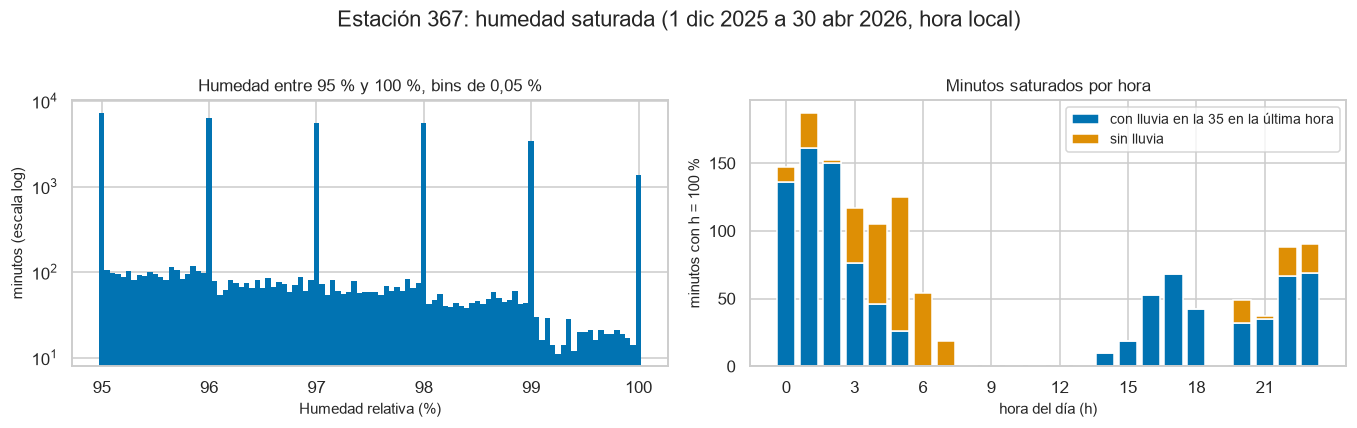

In [30]:
sat = m["h"] == 100
lluvia_35_1h = lluvia35.max(axis=1).fillna(0).rolling("60min").sum().reindex(m.index)
lluvia_367_1h = m["p"].fillna(0).rolling("60min").sum()
casi = (m["h"] >= 95) & (m["h"] < 100)
print("h = 100:", sat.sum(), "minutos en", sat.groupby(m.index.normalize()).any().sum(), "días")
print("por mes:", {MESES[p.month]: int(x) for p, x in sat.groupby(m.index.to_period("M")).sum().items()})
print(f"con lluvia en la 35 en la última hora: {(lluvia_35_1h[sat] > 0).mean():.1%} | en la 367: {(lluvia_367_1h[sat] > 0).mean():.1%}"
      f" | todos los minutos: {(lluvia_35_1h > 0).mean():.1%} | minutos con 95 <= h < 100: {(lluvia_35_1h[casi] > 0).mean():.1%}")
print("h > 100:", (m["h"] > 100).sum(), "| minutos con h exactamente entero, de 95 a 100:",
      {k: int((m["h"] == k).sum()) for k in range(95, 101)})
print("racha más larga de h = 100:", r100["minutos"].max(), "min, desde", r100.loc[r100["minutos"].idxmax(), "inicio"])
seco_sat = sat & (lluvia_35_1h == 0)
print("h = 100 sin lluvia en la 35 en la última hora:", seco_sat.sum(), "minutos; horas:",
      seco_sat.groupby(m.index.hour).sum().loc[lambda x: x > 0].to_dict(),
      "| entre las 3 y las 7 h:", seco_sat[m.index.hour.isin(range(3, 8))].sum())
fig, axs = plt.subplots(1, 2, figsize=(12.5, 3.8))
axs[0].hist(m["h"][m["h"] >= 95], bins=np.arange(94.975, 100.03, 0.05), color=COL[0], linewidth=0)
axs[0].set(yscale="log", xlabel=etiqueta("h"), ylabel="minutos (escala log)", title="Humedad entre 95 % y 100 %, bins de 0,05 %")
por_hora_sat = pd.DataFrame({"con lluvia en la 35 en la última hora": (sat & (lluvia_35_1h > 0)).groupby(m.index.hour).sum(),
                             "sin lluvia": seco_sat.groupby(m.index.hour).sum()}).reindex(range(24), fill_value=0)
axs[1].bar(por_hora_sat.index, por_hora_sat.iloc[:, 0], color=COL[0], label=por_hora_sat.columns[0])
axs[1].bar(por_hora_sat.index, por_hora_sat.iloc[:, 1], bottom=por_hora_sat.iloc[:, 0], color=COL[1], label="sin lluvia")
axs[1].set(xlabel="hora del día (h)", ylabel="minutos con h = 100 %", xticks=range(0, 24, 3), title="Minutos saturados por hora")
axs[1].legend(fontsize=9)
fig.suptitle(f"Estación 367: humedad saturada ({PERIODO})", y=1.02)
fig.tight_layout()
plt.show()

Es saturación real. Hay 1363 minutos en 100 % repartidos en 25 días, sobre todo en enero y febrero (546 y 547), y ninguno por encima de 100. En el 72,7 % hubo lluvia en la 35 en la hora previa (82,9 % en la 367), frente a 9,9 % del total de minutos y 27,5 % de los minutos con h entre 95 y 100 %. De los 372 minutos saturados sin lluvia, 272 caen entre las 3 y las 7 h, la hora más fría, lo que es compatible con niebla o rocío de madrugada (inferido: no hay sensor de visibilidad para comprobarlo). No hay señal de valor pegado por recorte: el 100 exacto tiene menos minutos (1363) que el 99 (3385) y el 98 (5495), la misma caída gradual que se ve desde 95. Los picos en cada entero del histograma son la resolución de 1 % de A1. La racha más larga en 100 % es de 145 minutos (25 feb 2026, de madrugada). Recomendación: no tratar h = 100 como error y recordar que la incertidumbre alcanzable de un sensor de estado sólido es de 3 % (OMM-8 Vol. I, 2023, Anexo 1.A, p. 26): 97 % y 100 % no se distinguen con certeza.

¿Las rachas de valores idénticos en `t`, `h` y `pr` son sensor congelado o atmósfera estable?

In [31]:
filas = {}
for v in ["t", "h", "pr"]:
    r = rachas(m[v])
    if v == "h":
        r = r[r["valor"] < 100]  # la saturación se analiza aparte
    largas = r[r["minutos"] >= 20]
    filas[v] = {"racha más larga (min)": r["minutos"].max(), "valor": r.loc[r["minutos"].idxmax(), "valor"],
                "inicio": r.loc[r["minutos"].idxmax(), "inicio"], "rachas >= 20 min": len(largas),
                "rachas >= 30 min": int((r["minutos"] >= 30).sum()),
                "% de rachas >= 20 min que empiezan de 18 a 07 h": round(100 * largas["inicio"].dt.hour.isin(
                    list(range(18, 24)) + list(range(0, 8))).mean(), 1)}
print(pd.DataFrame(filas).T.to_string())
inicio = filas["t"]["inicio"]
ventana = m.loc[inicio:inicio + pd.Timedelta(minutes=filas["t"]["racha más larga (min)"] - 1)]
print(f"\nDurante la racha más larga de t ({inicio}), valores distintos de otras columnas:",
      ventana[["h", "pr", "vv", "dv"]].nunique().to_dict())
pers = fallas[fallas["prueba"] == "persistencia"]
noche = pers["fecha_hora"].dt.hour.isin(list(range(19, 24)) + list(range(0, 7)))
print("\nMinutos marcados por la prueba de persistencia del control propio (ventana 60 min):")
print(pers.assign(noche=noche).groupby("variable").agg(minutos=("noche", "size"), pct_de_noche_19_a_06=("noche", "mean"))
      .assign(pct_de_noche_19_a_06=lambda x: (100 * x["pct_de_noche_19_a_06"]).round(1)))

   racha más larga (min)  valor               inicio rachas >= 20 min rachas >= 30 min % de rachas >= 20 min que empiezan de 18 a 07 h
t                     50   17.5  2026-04-30 01:46:00              113                8                                            98.2
h                     90   98.0  2026-02-15 01:23:00              639              205                                            98.1
pr                    48  816.8  2026-01-01 20:33:00               83               11                                            68.7

Durante la racha más larga de t (2026-04-30 01:46:00), valores distintos de otras columnas: {'h': 19, 'pr': 22, 'vv': 38, 'dv': 24}

Minutos marcados por la prueba de persistencia del control propio (ventana 60 min):
          minutos  pct_de_noche_19_a_06
variable                               
h            1827                  95.6
pr            132                  48.5
t             125                 100.0
vv           2258                  76.4


Son atmósfera estable. La racha más larga de t es de 50 minutos en 17,5 °C (30 abr 2026, 01:46), la de h (sin contar el 100) de 90 minutos en 98 % y la de pr de 48 minutos en 816,8 hPa. El 98,2 % de las rachas de t de 20 minutos o más y el 98,1 % de las de h empiezan entre las 18 y las 7 h, cuando el aire está quieto y la resolución de 0,1 °C y 1 % deja el valor sin cambio. Durante la racha de 50 minutos de t, h tomó 19 valores distintos, pr 22, `vv` 38 y `dv` 24: si el datalogger se hubiera congelado, todo se habría quedado quieto. En la presión solo el 68,7 % de las rachas largas son nocturnas; no se investigó la causa de las diurnas.

La prueba de persistencia del control propio (umbrales de la OMM, WMO-No. 488, ap. VI.2: 0,1 °C, 1 % y 0,1 hPa en 60 minutos; la humedad solo bajo 95 %) marca 125 minutos de t, todos de noche, y 1827 de h (95,6 % de noche). Como el umbral de t y pr es igual al paso del sensor, en noches estables marca datos reales. Propuesta para `calidad.py`: exigir valor idéntico en una ventana más larga de noche, o que varias variables estén quietas a la vez.

Otras coherencias entre columnas: lluvia con humedad baja y relación entre temperatura y humedad.

In [32]:
mojado = m["p"] > 0
print("minutos con lluvia y h < 60 %:", (mojado & (m["h"] < 60)).sum(), "de", mojado.sum(),
      "| con más de 0.02 mm y h < 60 %:", ((m["p"] > 0.02) & (m["h"] < 60)).sum())
print("mediana de h con lluvia:", m.loc[mojado, "h"].median(), "| sin lluvia:", m.loc[~mojado & m["p"].notna(), "h"].median())
an = horario[["t", "h"]].apply(anomalia)
print("Spearman t vs h, medias horarias:", round(horario["t"].corr(horario["h"], method="spearman"), 3),
      "| sin el ciclo diurno ni la media de 24 h:",
      round((an["t"] - an["t"].groupby(an.index.hour).transform("mean")).corr(
          an["h"] - an["h"].groupby(an.index.hour).transform("mean"), method="spearman"), 3))
print("saltos marcados por el control propio:", fallas[fallas["prueba"] == "salto"].groupby("variable").size().to_dict())

minutos con lluvia y h < 60 %: 118 de 9548 | con más de 0.02 mm y h < 60 %: 8
mediana de h con lluvia: 93.0 | sin lluvia: 86.0
Spearman t vs h, medias horarias: -0.913 | sin el ciclo diurno ni la media de 24 h: -0.847
saltos marcados por el control propio: {'h': 2, 'pr': 281, 'vv': 4}


Solo 118 de los 9548 minutos con lluvia tienen h menor que 60 % y apenas 8 superan 0,02 mm; la mediana de h con lluvia es 93 % frente a 86 % sin lluvia. Son pocos y pequeños y no ameritan una regla. t y h están muy anticorrelacionadas en las medias horarias (Spearman -0,913) y siguen en -0,847 después de quitar la media de 24 h y el ciclo diurno: la humedad relativa depende de la temperatura por definición, así que no es una relación entre dos fenómenos independientes.

¿Los saltos de presión de más de 0,5 hPa en un minuto son errores del barómetro?

In [33]:
t_sp = pd.DatetimeIndex(fallas.query("prueba == 'salto' and variable == 'pr'")["fecha_hora"])
print("minutos marcados por salto de pr (> 0.5 hPa):", len(t_sp), "en", t_sp.normalize().nunique(), "días",
      f"| entre las 10 y las 13 h: {t_sp.hour.isin([10, 11, 12, 13]).mean():.1%}")
dp = m["pr"].diff()
grande = dp.abs() > 0.5  # cada salto marca dos minutos en el control propio
print("saltos (pares de minutos):", grande.sum(), "| mayor cambio en un minuto:", round(dp.abs().max(), 2),
      "hPa | percentil 99.9 de |cambio|:", round(dp.abs().quantile(0.999), 2), "hPa")
signo = pd.crosstab(m.index.hour[grande], np.sign(dp[grande])).rename(columns={-1.0: "baja", 1.0: "sube"})
signo.index.name = "hora"
print("sentido del salto por hora:")
print(signo.T.to_string())
regreso = grande & (np.sign(dp.shift(-1)) == -np.sign(dp)) & (dp.shift(-1).abs() > 0.3)
print("saltos que se devuelven más de 0.3 hPa en el minuto siguiente (pico aislado):", regreso.sum())
print("pendiente máxima del ciclo medio S1 + S2:", round(np.abs(np.diff(s1 + s2) / np.diff(xx)).max() / 60, 4), "hPa/min")
print(f"minutos marcados con ráfaga >= 3 m/s: {(m.loc[t_sp, 'vv_max'] >= 3).mean():.1%} | "
      f"todos los minutos de 10 a 13 h: {(m.loc[m.index.hour.isin([10, 11, 12, 13]), 'vv_max'] >= 3).mean():.1%}")
print("ejemplo, 10 mar 2026:")
print(m.loc["2026-03-10 12:02":"2026-03-10 12:18", "pr"].to_string())

minutos marcados por salto de pr (> 0.5 hPa): 281 en 105 días | entre las 10 y las 13 h: 82.2%
saltos (pares de minutos): 150 | mayor cambio en un minuto: 1.44 hPa | percentil 99.9 de |cambio|: 0.41 hPa
sentido del salto por hora:
hora  1   9   10  11  12  13  14  15  16  17  19
pr                                              
baja   1   5  27  34  46  16   8   2   0   1   0
sube   0   0   0   0   0   0   2   2   3   2   1
saltos que se devuelven más de 0.3 hPa en el minuto siguiente (pico aislado): 3
pendiente máxima del ciclo medio S1 + S2: 0.019 hPa/min
minutos marcados con ráfaga >= 3 m/s: 17.4% | todos los minutos de 10 a 13 h: 12.9%
ejemplo, 10 mar 2026:
fecha_hora
2026-03-10 12:02:00    816.21
2026-03-10 12:03:00    816.20
2026-03-10 12:04:00    816.20
2026-03-10 12:05:00    816.05
2026-03-10 12:06:00    815.42
2026-03-10 12:07:00    815.50
2026-03-10 12:08:00    815.55
2026-03-10 12:09:00    815.59
2026-03-10 12:10:00    815.59
2026-03-10 12:11:00    815.51
2026-03-10 12:12:00 

Los 281 minutos marcados son 150 saltos en 105 días, y no parecen ruido del viento: 140 de los 150 son bajadas y los 128 que ocurren de 9 a 13 h son todos bajadas, justo cuando la marea hace caer la presión unos 5 hPa (A3). Solo 3 se devuelven en el minuto siguiente, así que no son picos aislados. La presión baja en escalones: el 10 mar 2026, por ejemplo, pasa de 816,05 a 815,42 hPa en un minuto, se queda cerca de 815,5 durante ocho minutos y baja a 814,46 en los dos siguientes. La pendiente máxima del ciclo medio es 0,019 hPa/min, más de 25 veces menor que el umbral del salto. La fracción de esos minutos con ráfaga de 3 m/s o más (17,4 %) es parecida a la del resto de las 10 a las 13 h (12,9 %). Inferido: el barómetro o su procesamiento actualiza el valor en escalones cuando la presión cae rápido (por histéresis o por un filtro); no se puede confirmar sin el manual del equipo. En medias de 10 o 60 minutos el efecto es pequeño; en el dato minutal, el valor puede ir atrasado algunos minutos.

## A6. Hallazgos priorizados

Prioridad según el daño que hace el problema si nadie lo corrige: alta si entrega datos falsos con calidad 1 a usuarios o alertas, media si sesga indicadores o el control de calidad, baja si es de forma o de monitoreo.

| # | Prioridad | Problema | Evidencia | Impacto | Recomendación |
|---|---|---|---|---|---|
| 1 | Alta | La dirección de ráfaga `dv_max` no sirve en el cuadrante 90° a 180° | Ahí toma solo 22 valores (88 o 89 en los otros cuadrantes) y tiene 9687 minutos frente a 40 168 de `dv`. Con viento de ese cuadrante la ráfaga coincide con la dirección media (menos de 22,5°) en 19,6 % y 26,8 % de los minutos, frente a 74,8 % a 96,9 % en los demás. Igual los cinco meses. Todo con calidad 1 | Cualquier rosa de ráfagas o dirección de viento extremo está sesgada. Ni `calidad` ni el control propio lo detectan | Revisar con el proveedor la conversión de `dv_max` en el datalogger. Mientras tanto, bandera 3 a `dv_max` cuando `dv` o `dv_max` caigan en [90, 180). Agregar al control una prueba de valores posibles (conteo por grado) |
| 2 | Alta | Fallas del anemómetro publicadas como dato bueno | 46 minutos con `vv`, `vv_max`, `dv` y `dv_max` en 0 a la vez (todos 1567). 20 de los 21 minutos con `vv` de 5 m/s o más y factor de ráfaga menor que 1,1 están a 30 min o menos de esos ceros. Meseta del 5 mar 2026: 12,85 m/s durante 9 minutos, factor 1,037, calidad 1 | El máximo de `vv` del periodo (13,47 m/s) es una falla; un umbral de alerta por viento se habría disparado | Tratar el cuádruple cero como malo (4), no como calma, y el `vv` de 5 m/s o más con `vv_max`/`vv` menor que 1,1 como sospechoso (3): las dos reglas ya están en el control propio (`viento_cuadruple_cero` y `factor_rafaga`). Falta marcar sospechosa la ventana de 30 min alrededor de un cuádruple cero. No tocar eventos como el del 5 feb 2026 (ráfaga de 14,3 m/s con caída de temperatura), que es real |
| 3 | Media | La columna `calidad` cambia de criterio y deja pasar problemas | 1511 no aparece en diciembre aunque 653 minutos cumplen la misma condición (p = 0,01 mm y la 35 en 0). 154 cubre 105 de los 1363 minutos con h = 100 (7,7 %). Los hallazgos 1 y 2 tienen calidad 1. Kappa con el control propio 0,053 | No sirve como etiqueta de verdad. Quien filtre por calidad = 1 se queda con datos malos | Publicar el diccionario de códigos de la 367 y la versión del algoritmo con su fecha de cambio. Reprocesar el histórico con la versión vigente |
| 4 | Media | La resolución real no es la que muestra el CSV y la prueba de persistencia marca datos reales | 55,1 % de los valores de h son enteros y 61,0 % de t y 60,3 % de pr son múltiplos de 0,1 (con paso de 0,01 serían 1 % y 10 %). La prueba de persistencia (0,1 °C en 60 min) marca 125 minutos de t, todos de noche. Durante la racha más larga de t (50 min) las demás columnas cambian | Falsos positivos del control en noches estables y decimales que aparentan una precisión que el sensor no tiene | Documentar la resolución nativa en el diccionario (h 1 %, t 0,1 °C, pr 0,1 hPa). En la persistencia, exigir valor idéntico en una ventana más larga de noche o que varias variables estén quietas a la vez |
| 5 | Media | La presión baja en escalones durante la caída diurna | 150 saltos de más de 0,5 hPa en un minuto (281 minutos marcados) en 105 días: 140 son bajadas y los 128 que ocurren de 9 a 13 h son todos bajadas; solo 3 se devuelven al minuto siguiente. La marea cambia la presión como máximo 0,019 hPa/min | La prueba de salto marca datos que probablemente son reales pero atrasados; un modelo minutal de pr confundiría los escalones con ruido | Dejarlos en sospechoso (3) sin borrar. Preguntar al proveedor por la actualización o el filtro del barómetro. Para modelar pr, usar medias de 10 a 60 minutos |
| 6 | Baja | Convención 0/360 mezclada y dirección reportada en calma | `dv` va de 0 a 359; `dv_max` tiene 260 minutos con 0 y 608 con 360. 20 464 de los 20 500 minutos de calma (0,2 m/s o menos) traen dirección | Una regla de rango o un conteo por grado sin normalizar trata distinto el mismo norte. La dirección en calma es ruido | Normalizar con `% 360`, reservar el 0 para la calma (OMM-8 Vol. I, 5.1.2, p. 207) y resumir la dirección con media vectorial ponderada por la velocidad |
| 7 | Baja | Huecos con patrón horario | 43 minutos en 22 huecos (completitud 99,98 %); 11 empiezan en el minuto :01 y 36 de los 43 minutos caen entre las 11 y las 16 h | Ninguno en los análisis; es una señal temprana del sistema de adquisición | Vigilar en el tablero la cantidad de huecos que empiezan en :01 |
| 8 | Informativo | La presión tiene un ciclo de 12 h tan fuerte como el de 24 h | Amplitud S2 = 1,52 hPa y S1 = 1,47 hPa; pico del periodograma en 12,0 h. La temperatura, como control, tiene S2/S1 = 0,39 | Un control de salto o un pronóstico de pr que ignore el ciclo de 12 h queda mal especificado | Incluir los armónicos de 24 y 12 h en los modelos de la Tarea B y en los controles de tendencia de pr |
| 9 | Informativo | La humedad de 100 % es saturación real | 72,7 % de esos minutos con lluvia en la 35 en la hora previa; 272 de los 372 minutos sin lluvia caen de 3 a 7 h. Sin acumulación anómala en 100 (1363 minutos frente a 3385 en 99) | Marcarla como error borraría niebla y lluvia reales | No marcar h = 100 como error. Revisar solo rachas de muchas horas en 100 % sin lluvia |

La comparación de la lluvia de la 367 con la 35 (mismo sitio) va en el notebook comparativo.

In [34]:
sorted(p.name for p in FIGURAS.glob("01_*.png"))

['01_dv_max_cuadrante.png',
 '01_presion_marea.png',
 '01_rosa_vientos.png',
 '01_viento_real_vs_falla.png']